# **PROJECT**: Data Preparation Pipeline

This notebook implements a full data preparation pipeline on the **'Comune di Milano - Servizi alla persona: parrucchieri ed estetisti'** dataset.

The process will follow these key steps:
1.  **Data Profiling & Quality Assessment:** Understand the raw data and its issues.
2.  **Data Cleaning:** Fix inconsistencies, typos, missing values, and duplicates.
3.  **Data Analysis:** an analysis will be performed on *both* the original (dirty) and the final (cleaned) dataset. Can be *classification*, *regression* or *clustering*.

The goal is to compare the performance metrics from both analyses to demonstrate the impact of a thorough cleaning process.

Import libraries:

In [1]:
from google.colab import drive
drive.mount("/gdrive")
current_dir = "/gdrive/My\\ Drive/[2025-2026]\\ DIQ/Project"
%cd $current_dir

Mounted at /gdrive
/gdrive/My Drive/[2025-2026] DIQ/Project


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime
import os
import re

Import data:

In [3]:
SERVIZI = pd.read_csv('italian/Comune-di-Milano-Servizi-alla-persona-parrucchieri-estetisti.csv',sep=';',encoding='unicode_escape')
SERVIZI

,Tipo esercizio pa,Ubicazione,Tipo via,Via,Civico,Codice via,ZD,Prevalente,Superficie altri usi,Superficie lavorativa
0,NaN,LGO DEI GELSOMINI N. 10 (z.d. 6),LGO,DEI GELSOMINI,10,5394.0,6,NaN,NaN,55.0
1,NaN,PZA FIDIA N. 3 (z.d. 9),PZA,FIDIA,3,1144.0,9,CENTRO MASSAGGI RILASSANTI NON ESTETICI,2.0,28.0
2,NaN,VIA ADIGE N. 10 (z.d. 5),VIA,ADIGE,10,4216.0,5,CENTRO BENESSERE,2.0,27.0
3,NaN,VIA BARACCHINI FLAVIO N. 9 (z.d. 1),VIA,BARACCHINI FLAVIO,9,356.0,1,TRUCCO SEMIPERMANENTE,NaN,NaN
4,NaN,VIA BERGAMO N. 12 (z.d. 4),VIA,BERGAMO,12,3189.0,4,NaN,NaN,50.0
...,...,...,...,...,...,...,...,...,...,...
3904,TIPO D ESTET.APPAR.ELETTROMECC;TIPO C TRATT.ES...,VIA SARPI FRA' PAOLO N. 1 con ingr.da v.le mon...,VIA,SARPI FRA' PAOLO,1,7210.0,1,NaN,NaN,NaN
3905,TIPO D ESTET.APPAR.ELETTROMECC;TIPO C TRATT.ES...,CSO DI PORTA TICINESE N. 4 ; (z.d. 1),CSO,DI PORTA TICINESE,4,541.0,1,NaN,NaN,65.0
3906,TIPO D ESTET.APPAR.ELETTROMECC;TIPO C TRATT.ES...,VIA CANDOGLIA N. 2 ; (z.d. 9),VIA,CANDOGLIA,2,1518.0,9,NaN,NaN,NaN
3907,TIPO D ESTET.APPAR.ELETTROMECC;TIPO C TRATT.ES...,VIA NIRONE num.002a; (z.d. 1),VIA,NIRONE,NaN,640.0,1,NaN,NaN,NaN


In [4]:
SERVIZI.shape

(3909, 10)

In [5]:
#show the schema of the data source
for column in SERVIZI.columns:
  print(column)

Tipo esercizio pa
Ubicazione
Tipo via
Via
Civico
Codice via
ZD
Prevalente
Superficie altri usi
Superficie lavorativa


In [6]:
SERVIZI.head(10)

,Tipo esercizio pa,Ubicazione,Tipo via,Via,Civico,Codice via,ZD,Prevalente,Superficie altri usi,Superficie lavorativa
0,NaN,LGO DEI GELSOMINI N. 10 (z.d. 6),LGO,DEI GELSOMINI,10,5394.0,6,NaN,NaN,55.0
1,NaN,PZA FIDIA N. 3 (z.d. 9),PZA,FIDIA,3,1144.0,9,CENTRO MASSAGGI RILASSANTI NON ESTETICI,2.0,28.0
2,NaN,VIA ADIGE N. 10 (z.d. 5),VIA,ADIGE,10,4216.0,5,CENTRO BENESSERE,2.0,27.0
3,NaN,VIA BARACCHINI FLAVIO N. 9 (z.d. 1),VIA,BARACCHINI FLAVIO,9,356.0,1,TRUCCO SEMIPERMANENTE,NaN,NaN
4,NaN,VIA BERGAMO N. 12 (z.d. 4),VIA,BERGAMO,12,3189.0,4,NaN,NaN,50.0
5,NaN,VIA BOTTEGO VITTORIO N. 13 (z.d. 2),VIA,BOTTEGO VITTORIO,13,2521.0,2,CENTRO BENESSERE,5.0,90.0
6,NaN,VIA BRIOSCHI FRANCESCO N. 39 (z.d. 5),VIA,BRIOSCHI FRANCESCO,39,5243.0,5,NaN,NaN,123.0
7,NaN,VIA CUCCHIARI DOMENICO N. 25 (z.d. 8),VIA,CUCCHIARI DOMENICO,25,7224.0,8,CENTRO MASSAGGI RILASSANTI NON ESTETICI,50.0,176.0
8,NaN,VIA JAN GIORGIO N. 6 (z.d. 3),VIA,JAN GIORGIO,6,2154.0,3,ESTETICA TIPO A,26.0,35.0
9,NaN,VIA LEGNONE N. 20 (z.d. 9),VIA,LEGNONE,20,1298.0,9,NaN,NaN,45.0


In [7]:
SERVIZI.dtypes

,0
Tipo esercizio pa,object
Ubicazione,object
Tipo via,object
Via,object
Civico,object
Codice via,float64
ZD,object
Prevalente,object
Superficie altri usi,float64
Superficie lavorativa,float64


In [8]:
SERVIZI['Codice via'].nunique()

1376

Check for null elements in each column

In [9]:
SERVIZI.isnull().sum()

,0
Tipo esercizio pa,31
Ubicazione,0
Tipo via,1
Via,1
Civico,77
Codice via,1
ZD,1
Prevalente,3615
Superficie altri usi,3164
Superficie lavorativa,1308


Visualizing all types of attribute 'Tipo Via'

In [10]:
SERVIZI['Tipo via'].value_counts()

,count
Tipo via,
VIA,2978
VLE,455
CSO,186
PZA,157
PLE,61
LGO,30
GLL,10
RIP,6
ALZ,6


#Data representation
In this section we will present data distribution for Superficie Lavorativa and Superficie Altri Usi, and Null Rate for each column through histograms

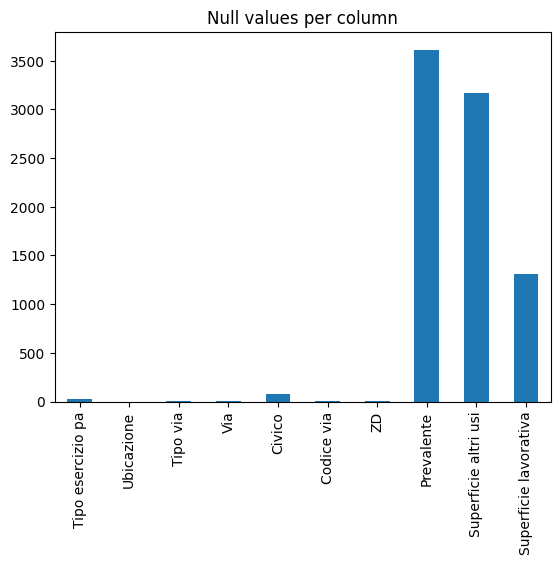

In [11]:
SERVIZI.isnull().sum().plot(kind='bar')
plt.title("Null values per column")
plt.savefig("null_values_per_column.png")
plt.show()

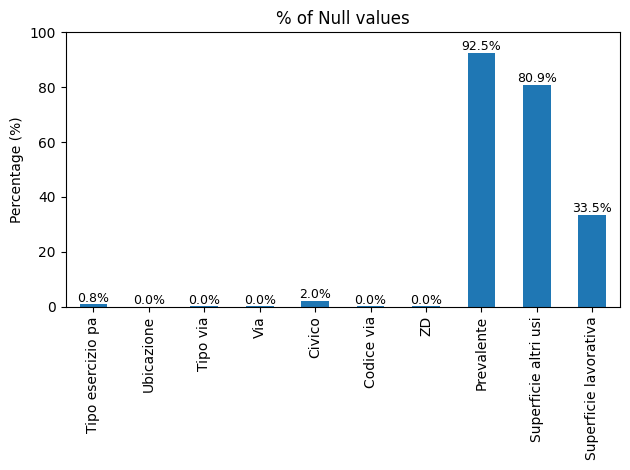

In [12]:
# Null percentage over the entire data set
null_percentage = (SERVIZI.isnull().sum() / len(SERVIZI)) * 100

# Graph plot
plt.figure()
null_percentage.plot(kind='bar')
plt.title("% of Null values")
plt.ylabel("Percentage (%)")
plt.ylim(0, 100)

# Labels
for i, v in enumerate(null_percentage):
    plt.text(i, v + 1, f"{v:.1f}%", ha='center', fontsize=9)

plt.tight_layout()
plt.savefig("percentage_null_values_per_column.png")
plt.show()

The following graph shows the distribution of Superficie Lavorativa; it is a skewed distribution, so the median becomes a more valid parameter compared to the mean.

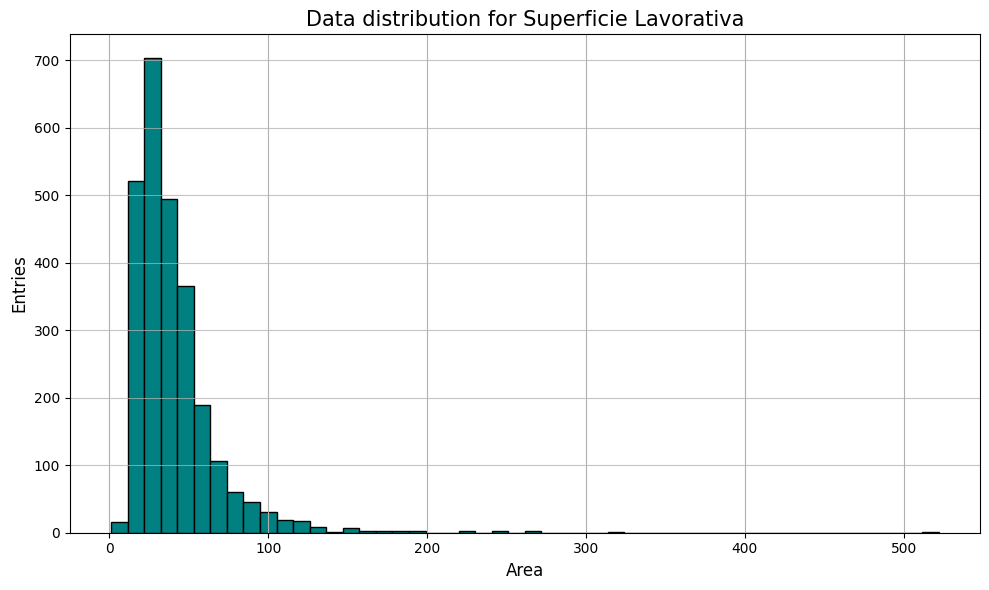

In [13]:
plt.figure(figsize=(10, 6))

SERVIZI['Superficie lavorativa'].dropna().hist(bins=50, color='teal', edgecolor='black')

plt.title('Data distribution for Superficie Lavorativa', fontsize=15)
plt.xlabel('Area', fontsize=12)
plt.ylabel('Entries', fontsize=12)
plt.grid(axis='y', alpha=0.75)

plt.tight_layout()
plt.savefig("data_distribution_sup_lav.png")
plt.show()

The same applies for the Superficie Altri Usi.

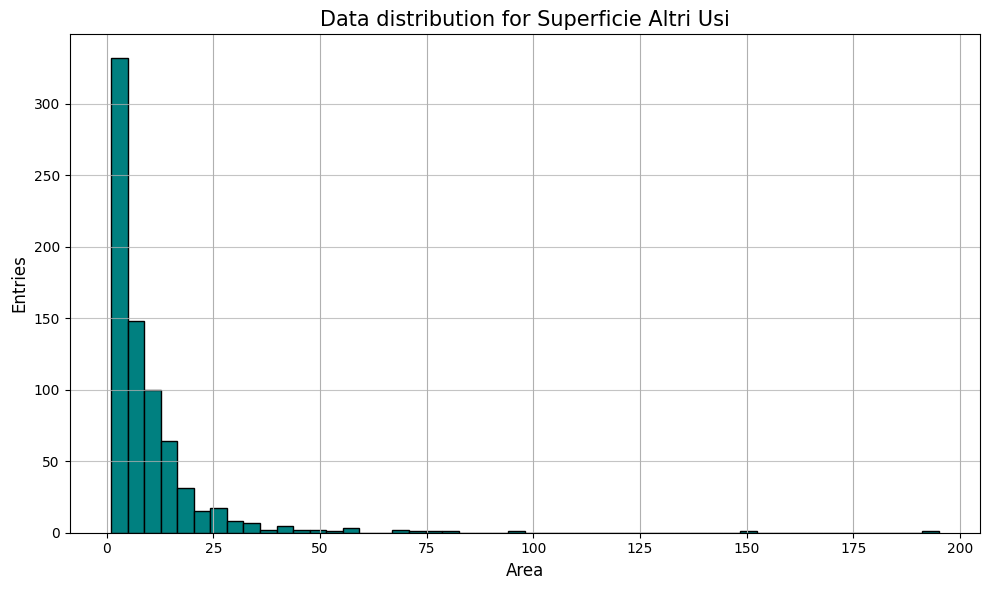

In [14]:
plt.figure(figsize=(10, 6))

SERVIZI['Superficie altri usi'].dropna().hist(bins=50, color='teal', edgecolor='black')

plt.title('Data distribution for Superficie Altri Usi', fontsize=15)
plt.xlabel('Area', fontsize=12)
plt.ylabel('Entries', fontsize=12)
plt.grid(axis='y', alpha=0.75)

plt.tight_layout()
plt.savefig("data_distribution_sup_altri_usi.png")
plt.show()

#Completeness evaluation
In this section we will perform completeness evaluation, to determine which features are worth keeping. Features with more than 50% of missing/wrong values will be dropped, while for the remaining features missing values will be determined by modal values.

In [15]:
# Null values for every column
null_counts = SERVIZI.isnull().sum()

# Null rate for every column
for col, count in null_counts.items():
    print(f"{col}: {(count / len(SERVIZI) * 100):.2f}%")

total_null_elements = null_counts.sum()
total_cells = SERVIZI.size
completeness_score = (1 - (total_null_elements / total_cells)) * 100

print("-" * 30)
print(f"Total null elements: {total_null_elements}")
print(f"Global Completeness Score: {completeness_score:.2f}%")

Tipo esercizio pa: 0.79%
Ubicazione: 0.00%
Tipo via: 0.03%
Via: 0.03%
Civico: 1.97%
Codice via: 0.03%
ZD: 0.03%
Prevalente: 92.48%
Superficie altri usi: 80.94%
Superficie lavorativa: 33.46%
------------------------------
Total null elements: 8199
Global Completeness Score: 79.03%


"Prevalente" and "Superficie altri usi" present a really high Null rate. They will be discarded because imputing the remaining values will lead to incorrect statistics. Prevalente can be extracted from tipo esercizio pa.

# Accuracy evaluation
In this section we calculate the accuracy of ZD, Codice Via, Civico, Superficie Altri Usi and Superficie Lavorativa (last two values must be non negative).

In [16]:
SERVIZI.isnull().sum()

,0
Tipo esercizio pa,31
Ubicazione,0
Tipo via,1
Via,1
Civico,77
Codice via,1
ZD,1
Prevalente,3615
Superficie altri usi,3164
Superficie lavorativa,1308


ZD domain is required to be inside the range 1-9, while the codice via is supposed to be inside the range 100-9999, based on the occurrences in this column.

In [17]:

ZD_domain = ['1','2','3','4','5','6','7','8','9']
not_null_ZD = SERVIZI['ZD'].count()
correct_ZD = SERVIZI['ZD'].astype(str).isin(ZD_domain).sum()
accuracy = correct_ZD/not_null_ZD
print(f"Accuracy of the ZD column: {accuracy*100:.2f}%")

correct_codice_via = SERVIZI['Codice via'].between(100, 9999).sum()
not_null_codice_via = SERVIZI['Codice via'].count()
accuracy = correct_codice_via/not_null_codice_via
print(f"Accuracy of the Codice via column: {accuracy*100:.2f}%")

Accuracy of the ZD column: 99.97%
Accuracy of the Codice via column: 99.87%


#Consistency evaluation
In this section we check the consistency level of Superificie Lavorativa, Superficie Altri Usi and Civico. We set a consistent value for the first two as any number greater or equal than zero, while Civico is considered consistent if it is inside an appropriate range (0-999).

In [18]:
#Regex pattern to match Civico in the form 000/A
regex_pattern = r"^(?:\d{1,3}(?:[\/\-]?[A-Za-z]+)?)$"

civ = SERVIZI["Civico"].astype("string")

correct_civico = civ.str.match(regex_pattern, na=False).sum()
not_null_civico = civ.notna().sum()

print(f"Consistent values in Civico: {correct_civico}")
print(f"Total values in Civico: {correct_civico}")
consistency = correct_civico / not_null_civico if not_null_civico else 0
print(f"Consistency of the Civico column: {consistency*100:.2f}%")

Consistent values in Civico: 3829
Total values in Civico: 3829
Consistency of the Civico column: 99.92%


Here we check that all the values of Superficie Lavorativa and Superficie Altri Usi are greater than 0.

In [19]:
correct_sup_a_u = (SERVIZI['Superficie altri usi'] > 0).sum()
not_null_sup_a_u = SERVIZI['Superficie altri usi'].count()
consistency = correct_sup_a_u/not_null_sup_a_u
print(f"Consistency of the Superficie Altri Usi column: {accuracy*100:.2f}%")

correct_sup_l = (SERVIZI['Superficie lavorativa'] > 0).sum()
not_null_sup_l = SERVIZI['Superficie lavorativa'].count()
consistency = correct_sup_l/not_null_sup_l
print(f"Consistency of the Superficie Lavorativa column: {accuracy*100:.2f}%")

Consistency of the Superficie Altri Usi column: 99.87%
Consistency of the Superficie Lavorativa column: 99.87%


The following code checks that the values in Tipo Via, Via and Civico are consistent with what we have in the Ubicazione column.

In [20]:
def check_presence(row, col_name, target_col):
    if pd.isnull(row[col_name]) or pd.isnull(row[target_col]):
        return False
    return str(row[col_name]).lower() in str(row[target_col]).lower()

check_tipo = SERVIZI.apply(check_presence, args=('Via', 'Ubicazione'), axis=1)
count_tipo = SERVIZI[['Tipo via', 'Ubicazione']].dropna().shape[0]
acc_tipo = (check_tipo.sum() / count_tipo * 100) if count_tipo > 0 else 0

check_nome = SERVIZI.apply(check_presence, args=('Via', 'Ubicazione'), axis=1)
count_nome = SERVIZI[['Via', 'Ubicazione']].dropna().shape[0]
acc_nome = (check_nome.sum() / count_nome * 100) if count_nome > 0 else 0

check_civico = SERVIZI.apply(check_presence, args=('Civico', 'Ubicazione'), axis=1)
count_civico = SERVIZI[['Civico', 'Ubicazione']].dropna().shape[0]
acc_civico = (check_civico.sum() / count_civico * 100) if count_civico > 0 else 0

print("Consistency of Ubicazione")
print(f"Tipo Via   in Ubicazione: {acc_tipo:.2f}%")
print(f"Nome Via   in Ubicazione: {acc_nome:.2f}%")
print(f"Civico     in Ubicazione: {acc_civico:.2f}%")

Consistency of Ubicazione
Tipo Via   in Ubicazione: 98.08%
Nome Via   in Ubicazione: 98.08%
Civico     in Ubicazione: 98.23%


#Timeliness evaluation
Since our dataset does not contain any direct or indirect reference to the insertion time of each row, it is not possible to calculate its timeliness.


#Data cleaning pipeline
To perform data cleaning, we will drop Ubicazione in favor of Tipo Via, Via and Civico. We will also drop Prevalente since it is composed of null values for the majority of its entries, and we will split the Tipo Attività into 4 boolean columns (Tipo A, B, C, D). This will also help with the Machine Learning problem (classification of Tipo Attività).

In [21]:
# The following code looks for rows in which both Prevalente and Tipo esercizio pa are Null;
# in this case it is not possible to retrieve useful information and therefore the row is dropped
empty_rows = SERVIZI['Tipo esercizio pa'].isnull() & SERVIZI['Prevalente'].isnull()
print(f"Empty rows: {empty_rows.sum()}")
SERVIZI = SERVIZI.dropna(subset=['Tipo esercizio pa', 'Prevalente'], how='all')

Empty rows: 16


In [22]:
# This code looks for unique values in Prevalente
cat = SERVIZI[SERVIZI['Prevalente'].notnull()]

print(cat['Prevalente'].unique())

['CENTRO MASSAGGI RILASSANTI NON ESTETICI' 'CENTRO BENESSERE'
 'TRUCCO SEMIPERMANENTE' 'ESTETICA TIPO A' 'CENTRO MASSAGGI'
 'TATUAGGI E PIERCING' 'SERVIZI DI CENTRI PER IL BENESSERE FISICO'
 'ESTETICA A' 'acconciatore' 'ACCONCIATORE'
 'SERVIZI DEI SALONI DI BARBIERE E PARRUCCHIERE' 'Acconciatore'
 'PARRUCCHIERE UOMO DONNA BARBIERE' 'PARRUCCHIERE' 'ACONCIATORE'
 'ACCONCIATORE UOMO DONNA' 'acconciatore.' 'ACCONCIATORE E ESTETICA'
 'CENTRO BENESSERE RILASSANTE NON ESTETICO'
 'CENTRO PER IL BENESSERE FISICO'
 'CENTTRO BENESSERE (ESCLUSI GLI STABILIMENTI TERMALI)'
 'SERVIZI DEI CENTRI E STABIL. PER IL BENESSERE FISICO' 'STUDIO OLISTICO'
 'CENTRO OLISTICO' 'centro massaggi' 'MASSAGGI RILASSANTI'
 'CENTRO MASSAGI RILASSANTI NON ESTETICI' 'CENTRO MASSAGGI TUINA'
 'CENTRO MASSAGGI RILASSANTI' 'SERVIZI DI CENTRI PER IL BENESSERE'
 "ATTIVITA' DI MASSAGGI RILASSANTI" 'MASSAGGI'
 'CENTRO MASSAGGI THAI RILASSANTI NON CURATIVI' 'centro benessere'
 'ESECUZIONE DI TATUAGGI E PIERCING' 'TATUAGGIO' 'tatu

The previous set of strings from "Prevalente"  and "Tipo esercizio pa" was used to find what was used instead of Tipo A, B, C, D to describe the activities. We built a filter that matches all those keywords from both "Tipo esercizio pa" and "Prevalente"into the 4 categories.

In [23]:
SERVIZI.loc[:, ['Tipo A', 'Tipo B', 'Tipo C', 'Tipo D']] = False

pattern_a = r"estetica|estetista|solarium|manicure|pedicure|tipo\s*a|manuale|reg\.2003|truccatore|trucco|estet\."

pattern_b = r"acconciatore|parrucchiere|barbiere|aconciatore|tipo\s*b|abbronzatura"

pattern_c = r"unghie|ricostruzione|onicotecnica|tipo\s*c|dimagrim"

pattern_d = r"benessere|massaggi|tatuaggi|piercing|olistico|thai|tipo\s*d|trucco|elettromecc"

pattern_all = r"a-b-c-d"

SERVIZI.loc[:, 'Tipo A'] = (SERVIZI['Tipo esercizio pa'].astype(str) + " " +
                            SERVIZI['Prevalente'].astype(str)).str.contains(pattern_a, case=False, na=False)
SERVIZI.loc[:, 'Tipo B'] = (SERVIZI['Tipo esercizio pa'].astype(str) + " " +
                            SERVIZI['Prevalente'].astype(str)).str.contains(pattern_b, case=False, na=False)
SERVIZI.loc[:, 'Tipo C'] = (SERVIZI['Tipo esercizio pa'].astype(str) + " " +
                            SERVIZI['Prevalente'].astype(str)).str.contains(pattern_c, case=False, na=False)
SERVIZI.loc[:, 'Tipo D'] = (SERVIZI['Tipo esercizio pa'].astype(str) + " " +
                            SERVIZI['Prevalente'].astype(str)).str.contains(pattern_d, case=False, na=False)

In [24]:
SERVIZI = SERVIZI.copy()

colonne_tipo = ['Tipo A', 'Tipo B', 'Tipo C', 'Tipo D']

# Searching all the rows in which those four columns are empty
mask_all_false = ~SERVIZI[colonne_tipo].any(axis=1)
useless_rows = SERVIZI[mask_all_false]

# Check before dropping rows
print(f"UNDEFINED ACTIVITIES")
print(f"Rows that will be dropped: {len(useless_rows)}")

if not useless_rows.empty:
    # Preview of rows that will be dropped
    print(useless_rows[['Tipo esercizio pa', 'Prevalente'] + colonne_tipo].head(10))

    # Drop over the original dataset
    SERVIZI.drop(useless_rows.index, inplace=True)
    print("\n[OK] Cleaning completed")
else:
    print("\n[OK] No row to be dropped. Dataset is clean")

# Check of remaining rows
print(f"Total rows after data cleaning: {len(SERVIZI)}")

# Drop Prevalente and Tipo esercizio pa columns
SERVIZI.drop(columns=["Prevalente"], inplace=True)
SERVIZI.drop(columns=["Tipo esercizio pa"], inplace=True)

UNDEFINED ACTIVITIES
Rows that will be dropped: 1
   Tipo esercizio pa Prevalente  Tipo A  Tipo B  Tipo C  Tipo D
33          (z.d. 9)        NaN   False   False   False   False

[OK] Cleaning completed
Total rows after data cleaning: 3892



##**Dropping Ubicazione**
In this section, our goal is to get rid of the "Ubicazione" column because of the redundant information it shares with Tipo Via, Via,Civico, Codice Via and ZD.

In [25]:
df = SERVIZI.copy()
print(df.isnull().sum())
df

#Obtain the number of null values in every column

COL_UBIC = "Ubicazione"
COL_TIPO = "Tipo via"
COL_VIA  = "Via"
COL_CIV  = "Civico"
COL_ZD   = "ZD"


Ubicazione                  0
Tipo via                    1
Via                         1
Civico                     77
Codice via                  1
ZD                          1
Superficie altri usi     3148
Superficie lavorativa    1305
Tipo A                      0
Tipo B                      0
Tipo C                      0
Tipo D                      0
dtype: int64


In [26]:
# Columns we want to use
cols = ["Tipo via", "Via", "Civico", "ZD"]

# Mask to find how many rows contain missing data
mask_missing_any = (
    df[cols].isna() |
    df[cols].astype(str).apply(lambda s: s.str.strip().str.lower().isin(["", "nan", "null", "none", "NaN"]))
).any(axis=1)

# Print the rows
print(
    f"Righe con almeno un campo mancante: {mask_missing_any.sum()} "
    f"({mask_missing_any.mean():.2%})"
)

df.loc[mask_missing_any, cols + ["Ubicazione"]].head(10)


Righe con almeno un campo mancante: 77 (1.98%)


,Tipo via,Via,Civico,ZD,Ubicazione
32,NaN,NaN,NaN,NaN,CSO COMO N. 15 interno club f. conti
286,VIA,APPENNINI,NaN,8,VIA APPENNINI num.077h; (z.d. 8)
308,VIA,BETTI UGO,NaN,8,VIA BETTI UGO num.161a; (z.d. 8)
317,VIA,BOIFAVA PIETRO,NaN,5,VIA BOIFAVA PIETRO num.006c; (z.d. 5)
319,VIA,FERMIGNANO,NaN,9,VIA BOVISASCA num.173; (z.d. 9)
328,VIA,CALVI PIETRO,NaN,4,VIA CALVI PIETRO p.t.acconciatore num.003a; (z...
379,VIA,D'ADDA CARLO,NaN,6,VIA D'ADDA CARLO num.001a; (z.d. 6)
425,VIA,FERMIGNANO,NaN,9,VIA FERMIGNANO num.003; (z.d. 9)
493,VIA,MAGGI CARLO MARIA,NaN,1,VIA MAGGI CARLO MARIA num.003; (z.d. 1)
639,VIA,SANZIO RAFFAELLO,NaN,7,VIA SANZIO RAFFAELLO ingr. via s. siro num.002...


In [27]:
# Pattern to march Civico
civico_extract_pattern = r"\b(\d{1,3}(?:[\/\-]?[A-Za-z]+)?)\b"

# Extraction (support column)
SERVIZI["Civico_from_Ubicazione"] = (
    SERVIZI["Ubicazione"]
      .astype("string")
      .str.extract(civico_extract_pattern, expand=False)
      .str.strip()
)

# Mask: rows that (a) require data recovering and rows with (b) a valid value
mask_extracted_valid = (
    mask_missing_any &
    SERVIZI["Civico_from_Ubicazione"].notna() &
    ~SERVIZI["Civico_from_Ubicazione"].str.lower().isin(["", "nan", "null", "none", "NaN"])
)
# Substitutions to be performed
n_sostituiti = int(mask_extracted_valid.sum())
print(f"Number of Civico replaced by Ubicazione: {n_sostituiti}")

SERVIZI.loc[mask_extracted_valid, "Civico"] = SERVIZI.loc[mask_extracted_valid, "Civico_from_Ubicazione"]

cols = ["Tipo via", "Via", "Civico", "ZD"]
SERVIZI.loc[mask_extracted_valid, cols + ["Ubicazione"] + ["Civico_from_Ubicazione"]].head(10)






Number of Civico replaced by Ubicazione: 77


,Tipo via,Via,Civico,ZD,Ubicazione,Civico_from_Ubicazione
32,NaN,NaN,15,NaN,CSO COMO N. 15 interno club f. conti,15
286,VIA,APPENNINI,077h,8,VIA APPENNINI num.077h; (z.d. 8),077h
308,VIA,BETTI UGO,161a,8,VIA BETTI UGO num.161a; (z.d. 8),161a
317,VIA,BOIFAVA PIETRO,006c,5,VIA BOIFAVA PIETRO num.006c; (z.d. 5),006c
319,VIA,FERMIGNANO,173,9,VIA BOVISASCA num.173; (z.d. 9),173
328,VIA,CALVI PIETRO,003a,4,VIA CALVI PIETRO p.t.acconciatore num.003a; (z...,003a
379,VIA,D'ADDA CARLO,001a,6,VIA D'ADDA CARLO num.001a; (z.d. 6),001a
425,VIA,FERMIGNANO,003,9,VIA FERMIGNANO num.003; (z.d. 9),003
493,VIA,MAGGI CARLO MARIA,003,1,VIA MAGGI CARLO MARIA num.003; (z.d. 1),003
639,VIA,SANZIO RAFFAELLO,002a,7,VIA SANZIO RAFFAELLO ingr. via s. siro num.002...,002a


In [28]:
# Drop support column
SERVIZI.drop(columns=["Civico_from_Ubicazione"], inplace=True)

In [29]:
# Check for unique values in Tipo Via
cat = SERVIZI[SERVIZI['Tipo via'].notnull()]
print(cat['Tipo via'].unique())
tipi_via = cat['Tipo via'].unique()

null_like = {"", "nan", "null", "none", "na", "NaN"}

mask_tipo_via_missing = (
    SERVIZI['Tipo via'].isna() |
    SERVIZI['Tipo via'].astype("string").str.strip().str.lower().isin(null_like)
)
print("Rows with missing Tipo Via:", int(mask_tipo_via_missing.sum()))


['PZA' 'VIA' 'VLE' 'CSO' 'PAS' 'PLE' 'ALZ' 'BST' 'FOR' 'LGO' 'VIE' 'VLO'
 'GLL' 'RIP' 'PTA' 'SIT']
Rows with missing Tipo Via: 1


In [30]:
pattern_tipo_via = r"\b(" + "|".join(map(re.escape, tipi_via)) + r")\b"

SERVIZI["TipoVia_from_Ubicazione"] = (
    SERVIZI["Ubicazione"]
      .astype("string")
      .str.upper()
      .str.extract(pattern_tipo_via, expand=False)
      .str.strip()
)

mask_tipo_via_extracted_valid = (
    mask_tipo_via_missing &
    SERVIZI["TipoVia_from_Ubicazione"].notna() &
    ~SERVIZI["TipoVia_from_Ubicazione"].str.lower().isin(null_like)
)

n_tipo_via_replaced = int(mask_tipo_via_extracted_valid.sum())
print(f"Number of 'Tipo Via' replaced by 'Ubicazione': {n_tipo_via_replaced}")

SERVIZI.loc[mask_tipo_via_extracted_valid, "Tipo via"] = SERVIZI.loc[mask_tipo_via_extracted_valid, "TipoVia_from_Ubicazione"]

cols = ["Tipo via", "Via", "Civico", "ZD"]
SERVIZI.loc[mask_tipo_via_extracted_valid, cols + ["Ubicazione", "TipoVia_from_Ubicazione"]].head(10)

Number of 'Tipo Via' replaced by 'Ubicazione': 1


,Tipo via,Via,Civico,ZD,Ubicazione,TipoVia_from_Ubicazione
32,CSO,NaN,15,NaN,CSO COMO N. 15 interno club f. conti,CSO


In [31]:
# Drop support column
SERVIZI.drop(columns=["TipoVia_from_Ubicazione"], inplace=True)

In [32]:
# Check for unique values in Via
cat = SERVIZI[SERVIZI['Via'].notnull()]
print(cat['Via'].unique())
via = cat['Via'].unique()

null_like = {"", "nan", "null", "none", "na", "NaN"}

mask_via_missing = (
    SERVIZI['Via'].isna() |
    SERVIZI['Via'].astype("string").str.strip().str.lower().isin(null_like)
)
print("Rows with missing 'Via':", int(mask_via_missing.sum()))

['FIDIA' 'ADIGE' 'BARACCHINI FLAVIO' ... 'DURER ALBERTO' 'CANDOGLIA'
 'NIRONE']
Rows with missing 'Via': 1


In [33]:
pattern_via = r"\b(" + "|".join(map(re.escape, via)) + r")\b"

SERVIZI["Via_from_Ubicazione"] = (
    SERVIZI["Ubicazione"]
      .astype("string")
      .str.upper()
      .str.extract(pattern_via, expand=False)
      .str.strip()
)

mask_via_extracted_valid = (
    mask_via_missing &
    SERVIZI["Via_from_Ubicazione"].notna() &
    ~SERVIZI["Via_from_Ubicazione"].str.lower().isin(null_like)
)

n_via_replaced = int(mask_tipo_via_extracted_valid.sum())
print(f"Number of 'Via' replaced from Ubicazione: {n_via_replaced}")

SERVIZI.loc[mask_via_extracted_valid, "Via"] = SERVIZI.loc[mask_via_extracted_valid, "Via_from_Ubicazione"]

cols = ["Tipo via", "Via", "Civico", "ZD"]
SERVIZI.loc[mask_via_extracted_valid, cols + ["Ubicazione", "Via_from_Ubicazione"]].head(10)

Number of 'Via' replaced from Ubicazione: 1


,Tipo via,Via,Civico,ZD,Ubicazione,Via_from_Ubicazione
32,CSO,COMO,15,NaN,CSO COMO N. 15 interno club f. conti,COMO


In [34]:
# Drop support column
SERVIZI.drop(columns=["Via_from_Ubicazione"], inplace=True)

In [35]:
# Check for Null values in ZD
null_like = {"", "nan", "null", "none", "na", "NaN"}

mask_zd_missing = (
    SERVIZI['ZD'].isna() |
    SERVIZI['ZD'].astype("string").str.strip().str.lower().isin(null_like)
)
print("Rows with missing 'ZD':", int(mask_zd_missing.sum()))

Rows with missing 'ZD': 1


In [36]:


zd_extract_pattern = r"(?i)\bz\s*\.?\s*d\s*\.?\s*[:\-]?\s*(\d+)\b"

# Extraction of data into support column
SERVIZI["ZD_from_Ubicazione"] = (
    SERVIZI["Ubicazione"]
      .astype("string")
      .str.extract(zd_extract_pattern, expand=False)
      .str.strip()
)

# Check for valid extracted value
mask_zd_extracted_valid = (
    mask_zd_missing
    & SERVIZI["ZD_from_Ubicazione"].notna()
    & SERVIZI["ZD_from_Ubicazione"].str.match(r"^\d+$", na=False)
)

# Replacement
n_zd_sostituiti = int(mask_zd_extracted_valid.sum())
print(f"Number of 'ZD' replaced from Ubicazione: {n_zd_sostituiti}")

SERVIZI.loc[mask_zd_extracted_valid, "ZD"] = SERVIZI.loc[mask_zd_extracted_valid, "ZD_from_Ubicazione"]

# Visual check
cols = ["Tipo via", "Via", "Civico", "ZD"]
SERVIZI.loc[mask_zd_extracted_valid, cols + ["Ubicazione", "ZD_from_Ubicazione"]].head(10)

Number of 'ZD' replaced from Ubicazione: 0


,Tipo via,Via,Civico,ZD,Ubicazione,ZD_from_Ubicazione


In [37]:
# Drop support column
SERVIZI.drop(columns=["ZD_from_Ubicazione"], inplace=True)

In [38]:
# Final check over the cleaned dataset
cols = ["Tipo via", "Via", "Civico", "ZD"]

# Mask: check for rows with at least an empty or NaN value across cols
new_mask_missing_any = (
    SERVIZI[cols].isna() |
    SERVIZI[cols].astype(str).apply(lambda s: s.str.strip().str.lower().isin(["", "nan", "null", "none", "NaN"]))
).any(axis=1)

print(
    f"Rows with at least an empty field: {new_mask_missing_any.sum()} "
    f"({new_mask_missing_any.mean():.2%})"
)

SERVIZI.loc[new_mask_missing_any, cols + ["Ubicazione"]].head(10)

Rows with at least an empty field: 1 (0.03%)


,Tipo via,Via,Civico,ZD,Ubicazione
32,CSO,COMO,15,NaN,CSO COMO N. 15 interno club f. conti


In [39]:
SERVIZI.drop(columns=["Ubicazione"], inplace=True)

In [40]:
# Numbers of row with the same Tipo Via
conteggio = SERVIZI['Tipo via'].value_counts()
print(conteggio)

Tipo via
VIA    2966
VLE     452
CSO     187
PZA     157
PLE      61
LGO      29
GLL      10
ALZ       6
RIP       6
FOR       5
BST       4
PTA       3
VLO       2
VIE       2
PAS       1
SIT       1
Name: count, dtype: int64


In [41]:
# Column normalization
SERVIZI['tipo_via_clean'] = SERVIZI['Tipo via'].str.lower().str.strip().str.replace('.', '', regex=False)
SERVIZI['via_clean'] = SERVIZI['Via'].str.lower().str.strip()
SERVIZI['civico_clean'] = SERVIZI['Civico'].astype(str).str.lower().str.strip()

# Sorting based on increasing number of null values; .first will take the most complete row
SERVIZI['null_count'] = SERVIZI.isnull().sum(axis=1)
SERVIZI = SERVIZI.sort_values('null_count')

# Rules for aggregation based on the considered column
# - Sum area values to account for fragmented information.
# - Max for 'Tipo X' flags to ensure the flag is set to 1 if at least one entry has it.
# - First for descriptive values to take the most complete non-null information available.

rules_agg = {}


for col in SERVIZI.columns:
    if col in ['Superficie altri usi', 'Superficie lavorativa']:
        rules_agg[col] = lambda x: x.sum(min_count=1)
    elif col in ['Tipo A', 'Tipo B', 'Tipo C', 'Tipo D']:
        rules_agg[col] = 'max'
    elif col not in ['via_clean', 'civico_clean', 'tipo_via_clean']:
        rules_agg[col] = 'first'

# Group by the cleaned keys and apply the aggregation rules
SERVIZI_cleaned = SERVIZI.groupby(['via_clean', 'civico_clean', 'tipo_via_clean']).agg(rules_agg).reset_index()

# 4. Final Cleanup
# Drop service columns used for merging and sorting
cols_to_drop = ['null_count', 'via_clean', 'civico_clean', 'tipo_via_clean']
SERVIZI_cleaned = SERVIZI_cleaned.drop(columns=[c for c in cols_to_drop if c in SERVIZI_cleaned.columns])

# Display results
print(f"Number of rows in the original dataset: {len(SERVIZI)}")
print(f"Number of rows in the cleaned dataset: {len(SERVIZI_cleaned)}")
print(f"Removed/merged records: {len(SERVIZI) - len(SERVIZI_cleaned)}")

Number of rows in the original dataset: 3892
Number of rows in the cleaned dataset: 3248
Removed/merged records: 644


In [42]:
# Check for duplicates
duplicates_check = SERVIZI[SERVIZI.duplicated(subset=['via_clean', 'civico_clean', 'tipo_via_clean'], keep=False)]

# Ordering based on similar values under via_clean and civico_clean
duplicates_check = duplicates_check.sort_values(['via_clean', 'civico_clean'])

# Visual check of found duplicates
print(duplicates_check.head(10))

     Tipo via                Via Civico  Codice via ZD  Superficie altri usi  \
2834      VIA  ABAMONTI GIUSEPPE      2      3135.0  3                   3.0   
2990      VIA  ABAMONTI GIUSEPPE      2      3135.0  3                   NaN   
3794      VLE            ABRUZZI     16      2177.0  3                   NaN   
2146      VLE            ABRUZZI     16      2177.0  3                   NaN   
2149      VLE            ABRUZZI     92      2177.0  3                   NaN   
3167      VLE            ABRUZZI     92      2177.0  3                   NaN   
3836      VIA      ACERBI ENRICO     34      1651.0  9                   NaN   
2354      VIA      ACERBI ENRICO     34      1651.0  9                   NaN   
2         VIA              ADIGE     10      4216.0  5                   2.0   
1325      VIA              ADIGE     10      4216.0  5                   NaN   

      Superficie lavorativa  Tipo A  Tipo B  Tipo C  Tipo D tipo_via_clean  \
2834                  111.0   False    Tr

In [43]:
# Total number of missing cells in the dataset
totale_nulli = SERVIZI_cleaned.isnull().sum().sum()
print(f"Total missing values: {totale_nulli}")

Total missing values: 3495


We used the IQR method to detect and convert surface area outliers into NaN values. This approach was chosen for its robustness against skewed distributions. It allowed us to replace erroneous entries with precise, category-based averages. We used an asymmetric version of IQR to not exclude legitimate values that are larger than usual, rather than a typing error.

In [44]:
for col in ['Superficie lavorativa', 'Superficie altri usi']:
    # Applying skewed IQR
    Q1 = SERVIZI_cleaned[col].quantile(0.25)
    Q3 = SERVIZI_cleaned[col].quantile(0.75)
    IQR = Q3 - Q1

    limite_sup = Q3 + 2.5 * IQR
    limite_inf = max(0, Q1 - 1.5 * IQR)

    # Outliers identification
    mask_outlier = (SERVIZI_cleaned[col] > limite_sup) | (SERVIZI_cleaned[col] < limite_inf)
    n_outlier = mask_outlier.sum()
    print(f"'{col}': found {n_outlier} outliers (Limits: {limite_inf:.2f} - {limite_sup:.2f})")

    # Changing outliers into NaN, allowing for data inference
    SERVIZI_cleaned.loc[mask_outlier, col] = pd.NA

    # print outliers
    outliers = SERVIZI_cleaned[mask_outlier]
    print(outliers)

print(" " * 30)
print("Outlier detection completed. Values are changed into NaN.")

'Superficie lavorativa': found 59 outliers (Limits: 0.00 - 126.50)
     Tipo via                      Via Civico  Codice via ZD  \
99        VIA                ARCHIMEDE     20      3086.0  4   
200       VIA  BATTISTOTTI SASSI LUISA     12      3273.0  4   
275       VLE                   BLIGNY     23      4045.0  5   
381       VIA                BRUSUGLIO     73      1550.0  9   
384       VIA        BRUZZESI GIACINTO     25      5388.0  6   
390       CSO             BUENOS AIRES     23      2129.0  3   
392       CSO             BUENOS AIRES     36      2129.0  3   
407       VIA  BUONARROTI MICHELANGELO     15      6253.0  7   
445       VIA             CALVI PIETRO   003a      3083.0  4   
447       VIA     CALZECCHI TEMISTOCLE      2      3241.0  3   
466       VIA           CANONICA LUIGI     13      7121.0  1   
605       VLE                  CERTOSA     41      7174.0  8   
674       CSO       COLOMBO CRISTOFORO      1      5114.0  6   
685       CSO                     COM

Now we will recover missing data in Superficie lavorativa by finding the mean of this parameter using all the available data from activities that belong to the same class (same Tipo Attività). If the current row is "unique", we will provide the global mean of the column. Superficie lavorativa will keep its value as 0, since it is possible that those NaN were introduced because those activities had no extra space.

In [45]:
# 1. Define columns and flags
surface_columns = ['Superficie lavorativa', 'Superficie altri usi']
tag_list = ['Tipo A', 'Tipo B', 'Tipo C', 'Tipo D']

for col in surface_columns:
    n_to_impute = SERVIZI_cleaned[col].isnull().sum()

    if n_to_impute > 0:
        if col == 'Superficie lavorativa':
            # STRATEGY A: Conditional imputation for 'Superficie lavorativa'
            # Calculates the mean based on the exact combination of tags
            profile_mean = SERVIZI_cleaned.groupby(tag_list)[col].transform('mean').round(2)
            SERVIZI_cleaned[col] = SERVIZI_cleaned[col].fillna(profile_mean)

            # Backup for orphan profiles (global mean)
            remaining_nulls = SERVIZI_cleaned[col].isnull().sum()
            if remaining_nulls > 0:
                SERVIZI_cleaned[col] = SERVIZI_cleaned[col].fillna(SERVIZI_cleaned[col].mean())
            print(f"Column '{col}': imputed {n_to_impute} values via profile mean.")

        else:
            # STRATEGY B: Replace NaN with 0 for 'Superficie altri usi'
            SERVIZI_cleaned[col] = SERVIZI_cleaned[col].fillna(0)
            print(f"Column '{col}': replaced {n_to_impute} NaN values with 0.")

    else:
        print(f"Column '{col}': no values to handle.")

# Final overall check
print("-" * 30)
print("Final check after intervention:")
print(SERVIZI_cleaned[surface_columns].isnull().sum())

Column 'Superficie lavorativa': imputed 1002 values via profile mean.
Column 'Superficie altri usi': replaced 2577 NaN values with 0.
------------------------------
Final check after intervention:
Superficie lavorativa    0
Superficie altri usi     0
dtype: int64


#Data Quality Dimensions after Data Cleaning Pipeline
Now we perform data quality analysis on the cleaned dataset, comparing the results with the values that we got from the dirty dataset.

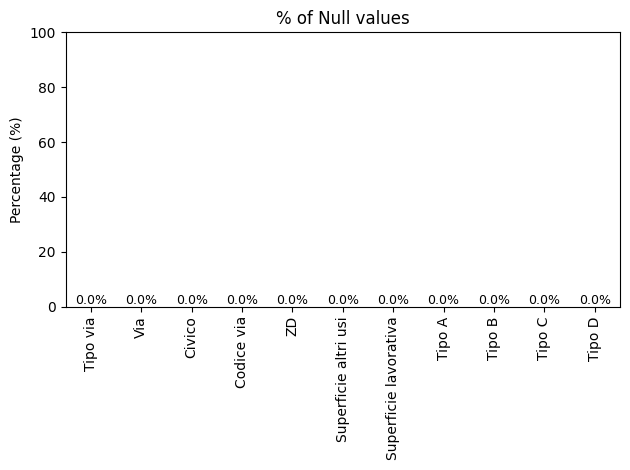

In [46]:
# New percentage of null values across the dataset (sum / total rows * 100)
null_percentage = (SERVIZI_cleaned.isnull().sum() / len(SERVIZI_cleaned)) * 100

plt.figure()
null_percentage.plot(kind='bar')
plt.title("% of Null values")
plt.ylabel("Percentage (%)")
plt.ylim(0, 100)

for i, v in enumerate(null_percentage):
    plt.text(i, v + 1, f"{v:.1f}%", ha='center', fontsize=9)

plt.tight_layout()
plt.show()

In [47]:
# Null values for every column
null_counts = SERVIZI_cleaned.isnull().sum()

# Null rate for every column
for col, count in null_counts.items():
    print(f"{col}: {(count / len(SERVIZI_cleaned) * 100):.2f}%")

total_null_elements = null_counts.sum()
total_cells = SERVIZI_cleaned.size
completeness_score = (1 - (total_null_elements / total_cells)) * 100

print("-" * 30)
print(f"Total null elements: {total_null_elements}")
print(f"Global Completeness Score: {completeness_score:.2f}%")

Tipo via: 0.00%
Via: 0.00%
Civico: 0.00%
Codice via: 0.00%
ZD: 0.00%
Superficie altri usi: 0.00%
Superficie lavorativa: 0.00%
Tipo A: 0.00%
Tipo B: 0.00%
Tipo C: 0.00%
Tipo D: 0.00%
------------------------------
Total null elements: 0
Global Completeness Score: 100.00%


In [48]:
ZD_domain = ['1','2','3','4','5','6','7','8','9']
not_null_ZD = SERVIZI_cleaned['ZD'].count()
correct_ZD = SERVIZI_cleaned['ZD'].astype(str).isin(ZD_domain).sum()
accuracy = correct_ZD/not_null_ZD
print(f"Accuracy of the ZD column: {accuracy*100:.2f}%")

correct_codice_via = SERVIZI_cleaned['Codice via'].between(1, 9999).sum()
not_null_codice_via = SERVIZI_cleaned['Codice via'].count()
accuracy = correct_codice_via/not_null_codice_via
print(f"Accuracy of the Codice via column: {accuracy*100:.2f}%")

Accuracy of the ZD column: 100.00%
Accuracy of the Codice via column: 100.00%


In [49]:
#Regex pattern to match Civico in the form 000/A
regex_pattern = r"^(?:\d{1,3}(?:[\/\-]?[A-Za-z]+)?)$"

civ = SERVIZI_cleaned["Civico"].astype("string")  # preserva <NA>

correct_civico = civ.str.match(regex_pattern, na=False).sum()
not_null_civico = civ.notna().sum()

print(correct_civico, not_null_civico)
consistency = correct_civico / not_null_civico if not_null_civico else 0
print(f"Consistency of the Civico column: {consistency*100:.2f}%")

3246 3248
Consistency of the Civico column: 99.94%


In [50]:
correct_sup_a_u = (SERVIZI_cleaned['Superficie altri usi'] > 0).sum()
not_null_sup_a_u = SERVIZI_cleaned['Superficie altri usi'].count()
consistency = correct_sup_a_u/not_null_sup_a_u
print(f"Consistency of the Superficie Altri Usi column: {accuracy*100:.2f}%")

correct_sup_l = (SERVIZI_cleaned['Superficie lavorativa'] > 0).sum()
not_null_sup_l = SERVIZI_cleaned['Superficie lavorativa'].count()
consistency = correct_sup_l/not_null_sup_l
print(f"Consistency of the Superficie Lavorativa column: {accuracy*100:.2f}%")

Consistency of the Superficie Altri Usi column: 100.00%
Consistency of the Superficie Lavorativa column: 100.00%


In [51]:
# Apply changes to the original dataset, change codice via into integer
SERVIZI = SERVIZI_cleaned.copy()
SERVIZI['Codice via'] = SERVIZI['Codice via'].astype('Int64')

print("Original dataset has been updated.")

Original dataset has been updated.


In [52]:
# save dataset to csv
SERVIZI.to_csv('italian/Comune-di-Milano-Servizi-alla-persona-parrucchieri-estetisti-cleaned.csv', index=False)

# **ML Analysis**

In [53]:
SERVIZI_CLEAN = SERVIZI.copy()

Import libraries:

In [54]:
import os
import sys
from google.colab import drive

drive.mount('/content/drive', force_remount=True)

project_path = "/content/drive/My Drive/[2025-2026] DIQ/Project"

if os.path.exists(project_path):
    os.chdir(project_path)
    print(f"Working directory is now: {os.getcwd()}")
else:
    print(f"Error: The folder '{project_path}' was not found.")
    print("Please verify the folder name in your Google Drive files sidebar on the left.")

Mounted at /content/drive
Working directory is now: /content/drive/My Drive/[2025-2026] DIQ/Project


In [55]:
from datetime import datetime

# Set seed for reproducibility
SEED = 42

# Import necessary libraries
import os

# Set environment variables before importing modules
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['MPLCONFIGDIR'] = os.getcwd() + '/configs/'

# Suppress warnings
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=Warning)

# Import necessary modules
import logging
import random
import numpy as np

# Set seeds for random number generators in NumPy and Python
np.random.seed(SEED)
random.seed(SEED)

# Import PyTorch
import torch
torch.manual_seed(SEED)
from torch import nn
from torchsummary import summary
from torch.utils.tensorboard import SummaryWriter
from torch.utils.data import TensorDataset, DataLoader
from torch.utils.data import WeightedRandomSampler
from sklearn.metrics import multilabel_confusion_matrix, classification_report
logs_dir = "tensorboard"
!pkill -f tensorboard
%load_ext tensorboard
!mkdir -p models

if torch.cuda.is_available():
    device = torch.device("cuda")
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
else:
    device = torch.device("cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")

# Import other libraries
import copy
import shutil
from itertools import product
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.model_selection import train_test_split

# Configure plot display settings
sns.set(font_scale=1.4)
sns.set_style('white')
plt.rc('font', size=14)
%matplotlib inline

PyTorch version: 2.9.0+cpu
Device: cpu


## ⏳ **Data Loading**

In [56]:
SERVIZI_UNCLEANED = pd.read_csv('italian/Comune-di-Milano-Servizi-alla-persona-parrucchieri-estetisti.csv',sep=';',encoding='unicode_escape')
SERVIZI_UNCLEANED

,Tipo esercizio pa,Ubicazione,Tipo via,Via,Civico,Codice via,ZD,Prevalente,Superficie altri usi,Superficie lavorativa
0,NaN,LGO DEI GELSOMINI N. 10 (z.d. 6),LGO,DEI GELSOMINI,10,5394.0,6,NaN,NaN,55.0
1,NaN,PZA FIDIA N. 3 (z.d. 9),PZA,FIDIA,3,1144.0,9,CENTRO MASSAGGI RILASSANTI NON ESTETICI,2.0,28.0
2,NaN,VIA ADIGE N. 10 (z.d. 5),VIA,ADIGE,10,4216.0,5,CENTRO BENESSERE,2.0,27.0
3,NaN,VIA BARACCHINI FLAVIO N. 9 (z.d. 1),VIA,BARACCHINI FLAVIO,9,356.0,1,TRUCCO SEMIPERMANENTE,NaN,NaN
4,NaN,VIA BERGAMO N. 12 (z.d. 4),VIA,BERGAMO,12,3189.0,4,NaN,NaN,50.0
...,...,...,...,...,...,...,...,...,...,...
3904,TIPO D ESTET.APPAR.ELETTROMECC;TIPO C TRATT.ES...,VIA SARPI FRA' PAOLO N. 1 con ingr.da v.le mon...,VIA,SARPI FRA' PAOLO,1,7210.0,1,NaN,NaN,NaN
3905,TIPO D ESTET.APPAR.ELETTROMECC;TIPO C TRATT.ES...,CSO DI PORTA TICINESE N. 4 ; (z.d. 1),CSO,DI PORTA TICINESE,4,541.0,1,NaN,NaN,65.0
3906,TIPO D ESTET.APPAR.ELETTROMECC;TIPO C TRATT.ES...,VIA CANDOGLIA N. 2 ; (z.d. 9),VIA,CANDOGLIA,2,1518.0,9,NaN,NaN,NaN
3907,TIPO D ESTET.APPAR.ELETTROMECC;TIPO C TRATT.ES...,VIA NIRONE num.002a; (z.d. 1),VIA,NIRONE,NaN,640.0,1,NaN,NaN,NaN


## 🔎 **Exploration and Data Analysis**

In [57]:
# Display the first 10 rows of the Glass dataset
SERVIZI_UNCLEANED.head(10)

,Tipo esercizio pa,Ubicazione,Tipo via,Via,Civico,Codice via,ZD,Prevalente,Superficie altri usi,Superficie lavorativa
0,NaN,LGO DEI GELSOMINI N. 10 (z.d. 6),LGO,DEI GELSOMINI,10,5394.0,6,NaN,NaN,55.0
1,NaN,PZA FIDIA N. 3 (z.d. 9),PZA,FIDIA,3,1144.0,9,CENTRO MASSAGGI RILASSANTI NON ESTETICI,2.0,28.0
2,NaN,VIA ADIGE N. 10 (z.d. 5),VIA,ADIGE,10,4216.0,5,CENTRO BENESSERE,2.0,27.0
3,NaN,VIA BARACCHINI FLAVIO N. 9 (z.d. 1),VIA,BARACCHINI FLAVIO,9,356.0,1,TRUCCO SEMIPERMANENTE,NaN,NaN
4,NaN,VIA BERGAMO N. 12 (z.d. 4),VIA,BERGAMO,12,3189.0,4,NaN,NaN,50.0
5,NaN,VIA BOTTEGO VITTORIO N. 13 (z.d. 2),VIA,BOTTEGO VITTORIO,13,2521.0,2,CENTRO BENESSERE,5.0,90.0
6,NaN,VIA BRIOSCHI FRANCESCO N. 39 (z.d. 5),VIA,BRIOSCHI FRANCESCO,39,5243.0,5,NaN,NaN,123.0
7,NaN,VIA CUCCHIARI DOMENICO N. 25 (z.d. 8),VIA,CUCCHIARI DOMENICO,25,7224.0,8,CENTRO MASSAGGI RILASSANTI NON ESTETICI,50.0,176.0
8,NaN,VIA JAN GIORGIO N. 6 (z.d. 3),VIA,JAN GIORGIO,6,2154.0,3,ESTETICA TIPO A,26.0,35.0
9,NaN,VIA LEGNONE N. 20 (z.d. 9),VIA,LEGNONE,20,1298.0,9,NaN,NaN,45.0


In [58]:
print('Servizi dataset shape', SERVIZI_UNCLEANED.shape)

SERVIZI_UNCLEANED.dtypes

Servizi dataset shape (3909, 10)


,0
Tipo esercizio pa,object
Ubicazione,object
Tipo via,object
Via,object
Civico,object
Codice via,float64
ZD,object
Prevalente,object
Superficie altri usi,float64
Superficie lavorativa,float64


## 🔄 **Data Preprocessing**

In [59]:
SERVIZI_UNCLEANED.loc[:, ['Tipo A', 'Tipo B', 'Tipo C', 'Tipo D']] = False

pattern_a = r"estetica|estetista|solarium|manicure|pedicure|tipo\s*a|manuale|reg\.2003|truccatore|trucco|estet\."

pattern_b = r"acconciatore|parrucchiere|barbiere|aconciatore|tipo\s*b|abbronzatura"

pattern_c = r"unghie|ricostruzione|onicotecnica|tipo\s*c|dimagrim"

pattern_d = r"benessere|massaggi|tatuaggi|piercing|olistico|thai|tipo\s*d|trucco|elettromecc"

pattern_all = r"a-b-c-d"

SERVIZI_UNCLEANED.loc[:, 'Tipo A'] = (SERVIZI_UNCLEANED['Tipo esercizio pa'].astype(str) + " " +
                            SERVIZI_UNCLEANED['Prevalente'].astype(str)).str.contains(pattern_a, case=False, na=False)
SERVIZI_UNCLEANED.loc[:, 'Tipo B'] = (SERVIZI_UNCLEANED['Tipo esercizio pa'].astype(str) + " " +
                            SERVIZI_UNCLEANED['Prevalente'].astype(str)).str.contains(pattern_b, case=False, na=False)
SERVIZI_UNCLEANED.loc[:, 'Tipo C'] = (SERVIZI_UNCLEANED['Tipo esercizio pa'].astype(str) + " " +
                            SERVIZI_UNCLEANED['Prevalente'].astype(str)).str.contains(pattern_c, case=False, na=False)
SERVIZI_UNCLEANED.loc[:, 'Tipo D'] = (SERVIZI_UNCLEANED['Tipo esercizio pa'].astype(str) + " " +
                            SERVIZI_UNCLEANED['Prevalente'].astype(str)).str.contains(pattern_d, case=False, na=False)

In [60]:
SERVIZI_UNCLEANED = SERVIZI_UNCLEANED.copy()

colonne_tipo = ['Tipo A', 'Tipo B', 'Tipo C', 'Tipo D']

# Searching all the rows in which those four columns are empty
mask_all_false = ~SERVIZI_UNCLEANED[colonne_tipo].any(axis=1)
useless_rows = SERVIZI_UNCLEANED[mask_all_false]

# Check before dropping rows
print(f"UNDEFINED ACTIVITIES")
print(f"Rows that will be dropped: {len(useless_rows)}")

if not useless_rows.empty:
    # Preview of rows that will be dropped
    print(useless_rows[['Tipo esercizio pa', 'Prevalente'] + colonne_tipo].head(10))

    # Drop over the original dataset
    SERVIZI_UNCLEANED.drop(useless_rows.index, inplace=True)
    print("\n[OK] Cleaning completed")
else:
    print("\n[OK] No row to be dropped. Dataset is clean")

# Check of remaining rows
print(f"Total rows after data cleaning: {len(SERVIZI_UNCLEANED)}")

# Drop Prevalente and Tipo esercizio pa columns
SERVIZI_UNCLEANED.drop(columns=["Prevalente"], inplace=True)
SERVIZI_UNCLEANED.drop(columns=["Tipo esercizio pa"], inplace=True)

UNDEFINED ACTIVITIES
Rows that will be dropped: 17
   Tipo esercizio pa Prevalente  Tipo A  Tipo B  Tipo C  Tipo D
0                NaN        NaN   False   False   False   False
4                NaN        NaN   False   False   False   False
6                NaN        NaN   False   False   False   False
9                NaN        NaN   False   False   False   False
12               NaN        NaN   False   False   False   False
13               NaN        NaN   False   False   False   False
15               NaN        NaN   False   False   False   False
17               NaN        NaN   False   False   False   False
18               NaN        NaN   False   False   False   False
19               NaN        NaN   False   False   False   False

[OK] Cleaning completed
Total rows after data cleaning: 3892


In [61]:
feature_cols = ['ZD', 'Tipo via', 'Superficie altri usi', 'Superficie lavorativa']
target_cols = ['Tipo A', 'Tipo B', 'Tipo C', 'Tipo D']

df = SERVIZI_UNCLEANED[feature_cols + target_cols].copy()

In [62]:
# Convert to numeric, turning any text errors (unclear ZD) into NaN
df['ZD'] = pd.to_numeric(df['ZD'], errors='coerce')

# dropping rows where ZD is NaN
df = df.dropna(subset=['ZD'])

# Convert ZD to integer
df['ZD'] = df['ZD'].astype(int)

In [63]:
df['Superficie altri usi'] = df['Superficie altri usi'].fillna(0.0)
df['Superficie lavorativa'] = df['Superficie lavorativa'].fillna(0.0)

In [64]:
df['Tipo via'] = df['Tipo via'].astype(str).str.upper().str.strip()

In [65]:
df = pd.get_dummies(df, columns=['Tipo via'], dtype=float)

In [66]:
# Final check of the prepared dataframe
print(df.info())
print("\nSample check:\n", df.head())

<class 'pandas.core.frame.DataFrame'>
Index: 3891 entries, 1 to 3908
Data columns (total 23 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   ZD                     3891 non-null   int64  
 1   Superficie altri usi   3891 non-null   float64
 2   Superficie lavorativa  3891 non-null   float64
 3   Tipo A                 3891 non-null   bool   
 4   Tipo B                 3891 non-null   bool   
 5   Tipo C                 3891 non-null   bool   
 6   Tipo D                 3891 non-null   bool   
 7   Tipo via_ALZ           3891 non-null   float64
 8   Tipo via_BST           3891 non-null   float64
 9   Tipo via_CSO           3891 non-null   float64
 10  Tipo via_FOR           3891 non-null   float64
 11  Tipo via_GLL           3891 non-null   float64
 12  Tipo via_LGO           3891 non-null   float64
 13  Tipo via_PAS           3891 non-null   float64
 14  Tipo via_PLE           3891 non-null   float64
 15  Tipo via_

In [67]:
# Analyze target distributions
for col in target_cols:
    print(f"\nAnalyzing Target: {col}")
    target = df[col].fillna(0).astype(int).values

    print(f'Target shape: {target.shape}')

    unique, count = np.unique(target, return_counts=True)

    print('Target labels:', unique)
    for i in range(len(unique)):
        label = "True (1)" if unique[i] == 1 else "False (0)"
        print(f'Class {unique[i]} ({label}) has {count[i]} samples')


Analyzing Target: Tipo A
Target shape: (3891,)
Target labels: [0 1]
Class 0 (False (0)) has 2610 samples
Class 1 (True (1)) has 1281 samples

Analyzing Target: Tipo B
Target shape: (3891,)
Target labels: [0 1]
Class 0 (False (0)) has 759 samples
Class 1 (True (1)) has 3132 samples

Analyzing Target: Tipo C
Target shape: (3891,)
Target labels: [0 1]
Class 0 (False (0)) has 3751 samples
Class 1 (True (1)) has 140 samples

Analyzing Target: Tipo D
Target shape: (3891,)
Target labels: [0 1]
Class 0 (False (0)) has 3614 samples
Class 1 (True (1)) has 277 samples


In [68]:
# Split dataset into Train, Validation, and Test sets

X = df.drop(columns=target_cols).astype(np.float32).values
y = df[target_cols].astype(np.int64).values

y_strat = ["".join(map(str, row)) for row in y]

X_train_val, X_test, y_train_val, y_test, y_strat_train, _ = train_test_split(
    X,
    y,
    y_strat,
    test_size=0.1,
    random_state=42,
    stratify=y_strat
)


X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.11,   # 11% of the remaining 90% ≈ 10% of total
    random_state=42,
    stratify=y_strat_train
)

# Show final dataset sizes
print(f'Training set shape:   {X_train.shape} {y_train.shape}')
print(f'Validation set shape: {X_val.shape}   {y_val.shape}')
print(f'Test set shape:       {X_test.shape}  {y_test.shape}')

Training set shape:   (3115, 19) (3115, 4)
Validation set shape: (386, 19)   (386, 4)
Test set shape:       (390, 19)  (390, 4)


In [69]:
input_features = X_train.shape[1]
print(f'Number of input features: {input_features}')

num_classes = y_train.shape[1]
print(f'Number of classes (output labels): {num_classes}')

Number of input features: 19
Number of classes (output labels): 4


In [70]:
# outlier removal needed for loss calculation

upper_limit = np.percentile(X_train, 99.5, axis=0)
X_train = np.minimum(X_train, upper_limit)
X_val   = np.minimum(X_val, upper_limit)
X_test  = np.minimum(X_test, upper_limit)

# Normalization
epsilon = 1e-8
max_df = X_train.max(axis=0)
min_df = X_train.min(axis=0)

print(f"Max raw value used for scaling: {max_df}")

def safe_scale(data, min_v, max_v):
    return (data - min_v) / (max_v - min_v + epsilon)

X_train = safe_scale(X_train, min_df, max_df)
X_val   = safe_scale(X_val,   min_df, max_df)
X_test  = safe_scale(X_test,  min_df, max_df)

print(f"New Max X_train: {X_train.max():.4f}")
print(f"New Max X_val:   {X_val.max():.4f}")

Max raw value used for scaling: [  9.        36.289795 157.         0.         0.         1.
   0.         0.         1.         0.         1.         0.
   1.         0.         0.         1.         0.         1.
   0.      ]
New Max X_train: 1.0000
New Max X_val:   1.0000


In [71]:
# Convert numpy arrays to PyTorch datasets (pairs features with labels)
train_ds = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train))
val_ds   = TensorDataset(torch.from_numpy(X_val), torch.from_numpy(y_val))
test_ds  = TensorDataset(torch.from_numpy(X_test), torch.from_numpy(y_test))

In [72]:
# Define the batch size, which is the number of samples in each batch
BATCH_SIZE = 16

In [73]:
def make_loader(ds, batch_size, shuffle, drop_last):
    # Determine optimal number of worker processes for data loading
    cpu_cores = os.cpu_count() or 2
    num_workers = max(2, min(4, cpu_cores))

    # Create DataLoader with performance optimizations
    return DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers,
        pin_memory=True,
        pin_memory_device="cuda" if torch.cuda.is_available() else "",
        prefetch_factor=4,
    )

In [74]:
# Create data loaders with different settings for each phase
train_loader = make_loader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=False)
val_loader   = make_loader(val_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)
test_loader  = make_loader(test_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)

In [75]:
# Get one batch from the training data loader
for xb, yb in train_loader:
    print("Features batch shape:", xb.shape)
    print("Labels batch shape:", yb.shape)
    break # Stop after getting one batch

Features batch shape: torch.Size([16, 19])
Labels batch shape: torch.Size([16, 4])


## 🛠️ **Model Building**

In [76]:
# Model architecture configuration
HIDDEN_LAYERS = 2
HIDDEN_SIZE = 256

In [77]:
# Define a simple feedforward neural network
class FeedForwardNet(nn.Module):
    def __init__(self, in_features=input_features, hidden_layers=1, hidden_size=16, dropout_rate=0.0, num_classes=num_classes):
        super().__init__()
        modules = []
        # First layer
        modules.append(nn.Linear(in_features, hidden_size))
        if dropout_rate > 0 :
            modules.append(nn.Dropout(dropout_rate)) # Probability of shutting down a neuron
        modules.append(nn.ReLU())

        # Additional hidden layers
        for _ in range(hidden_layers):
            modules.append(nn.Linear(hidden_size, hidden_size))
            if dropout_rate > 0 :
                modules.append(nn.Dropout(dropout_rate))
            modules.append(nn.ReLU())

        # Output layer
        modules.append(nn.Linear(hidden_size, num_classes))
        self.net = nn.Sequential(*modules)

    def forward(self, x):
        return self.net(x)

In [78]:
num_positives = torch.tensor(y_train.sum(axis=0), dtype=torch.float32)
num_negatives = torch.tensor(len(y_train) - num_positives, dtype=torch.float32)

pos_weight = (num_negatives / (num_positives + 1e-5)).to(device)

print("Calculated Class Weights:", pos_weight)

Calculated Class Weights: tensor([ 2.0361,  0.2430, 26.8125, 13.0315])


In [79]:
# Training configuration
LEARNING_RATE = 1e-4
EPOCHS = 500

PATIENCE = 20

L2_LAMBDA = 1e-4
DROPOUT_RATE = 0.3

# Set up loss function and optimizer
model = FeedForwardNet(hidden_layers=HIDDEN_LAYERS, hidden_size=HIDDEN_SIZE, dropout_rate=DROPOUT_RATE).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=L2_LAMBDA)

# Enable mixed precision training for GPU acceleration
scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

summary(model, input_size=(input_features,))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Linear-1                  [-1, 256]           5,120
           Dropout-2                  [-1, 256]               0
              ReLU-3                  [-1, 256]               0
            Linear-4                  [-1, 256]          65,792
           Dropout-5                  [-1, 256]               0
              ReLU-6                  [-1, 256]               0
            Linear-7                  [-1, 256]          65,792
           Dropout-8                  [-1, 256]               0
              ReLU-9                  [-1, 256]               0
           Linear-10                    [-1, 4]           1,028
Total params: 137,732
Trainable params: 137,732
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.00
Forward/backward pass size (MB): 0.02
Params size (MB): 0.53
Estimated T

In [80]:
# Set up TensorBoard logging and save model architecture
experiment_name = "baseline"
writer = SummaryWriter("./"+logs_dir+"/"+experiment_name)
x = torch.randn(1, input_features).to(device)
writer.add_graph(model, x)
writer.close()

## 🧠 **Model Training**

In [81]:
# Initialize best model tracking variables
best_model = None
best_performance = float('-inf')

In [82]:
def train_one_epoch(model, train_loader, criterion, optimizer, scaler, device, l1_lambda=0, l2_lambda=0):
    """
    Perform one complete training epoch through the entire training dataset.

    Args:
        model (nn.Module): The neural network model to train
        train_loader (DataLoader): PyTorch DataLoader containing training data batches
        criterion (nn.Module): Loss function (e.g., CrossEntropyLoss, MSELoss)
        optimizer (torch.optim): Optimization algorithm (e.g., Adam, SGD)
        scaler (GradScaler): PyTorch's gradient scaler for mixed precision training
        device (torch.device): Computing device ('cuda' for GPU, 'cpu' for CPU)
        l1_lambda (float): Lambda for L1 regularization
        l2_lambda (float): Lambda for L2 regularization

    Returns:
        tuple: (average_loss, f1 score) - Training loss and f1 score for this epoch
    """
    model.train()  # Set model to training mode

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    # Iterate through training batches
    for batch_idx, (inputs, targets) in enumerate(train_loader):
        # Move data to device (GPU/CPU)
        inputs, targets = inputs.to(device), targets.to(device).float()

        # Clear gradients from previous step
        optimizer.zero_grad(set_to_none=True)

        # Forward pass with mixed precision (if CUDA available)
        with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
            logits = model(inputs)
            loss = criterion(logits, targets)

            # Add L1 and L2 regularization
            l1_norm = sum(p.abs().sum() for p in model.parameters())
            l2_norm = sum(p.pow(2).sum() for p in model.parameters())
            loss = loss + l1_lambda * l1_norm + l2_lambda * l2_norm


        # Backward pass with gradient scaling
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        # Accumulate metrics
        running_loss += loss.item() * inputs.size(0)
        probs = torch.sigmoid(logits)
        predictions = (probs > 0.5).int()

        all_predictions.append(predictions.cpu().numpy())
        all_targets.append(targets.cpu().numpy())

    # Calculate epoch metrics
    epoch_loss = running_loss / len(train_loader.dataset)
    y_true = np.vstack(all_targets)
    y_pred = np.vstack(all_predictions)

    # Calculate F1 (Weighted handles label imbalance well)
    epoch_f1 = f1_score(y_true, y_pred, average='weighted', zero_division=0)

    return epoch_loss, epoch_f1

In [83]:
def validate_one_epoch(model, val_loader, criterion, device):
    """
    Perform one complete validation epoch through the entire validation dataset.

    Args:
        model (nn.Module): The neural network model to evaluate (must be in eval mode)
        val_loader (DataLoader): PyTorch DataLoader containing validation data batches
        criterion (nn.Module): Loss function used to calculate validation loss
        device (torch.device): Computing device ('cuda' for GPU, 'cpu' for CPU)

    Returns:
        tuple: (average_loss, accuracy) - Validation loss and accuracy for this epoch

    Note:
        This function automatically sets the model to evaluation mode and disables
        gradient computation for efficiency during validation.
    """
    model.eval()  # Set model to evaluation mode

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    # Disable gradient computation for validation
    with torch.no_grad():
        for inputs, targets in val_loader:
            # Move data to device
            inputs, targets = inputs.to(device), targets.to(device).float()

            # Forward pass with mixed precision (if CUDA available)
            with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
                logits = model(inputs)
                loss = criterion(logits, targets)

            # Accumulate metrics
            running_loss += loss.item() * inputs.size(0)
            probs = torch.sigmoid(logits)
            predictions = (probs > 0.5).int()

            all_predictions.append(predictions.cpu().numpy())
            all_targets.append(targets.cpu().numpy())

    # Calculate epoch metrics
    epoch_loss = running_loss / len(val_loader.dataset)
    y_true = np.vstack(all_targets)
    y_pred = np.vstack(all_predictions)

    epoch_accuracy = f1_score(y_true, y_pred, average='weighted', zero_division=0)

    return epoch_loss, epoch_accuracy

In [84]:
def log_metrics_to_tensorboard(writer, epoch, train_loss, train_f1, val_loss, val_f1, model):
    """
    Log training metrics and model parameters to TensorBoard for visualization.

    Args:
        writer (SummaryWriter): TensorBoard SummaryWriter object for logging
        epoch (int): Current epoch number (used as x-axis in TensorBoard plots)
        train_loss (float): Training loss for this epoch
        train_f1 (float): Training f1 score for this epoch
        val_loss (float): Validation loss for this epoch
        val_f1 (float): Validation f1 score for this epoch
        model (nn.Module): The neural network model (for logging weights/gradients)

    Note:
        This function logs scalar metrics (loss/f1 score) and histograms of model
        parameters and gradients, which helps monitor training progress and detect
        issues like vanishing/exploding gradients.
    """
    # Log scalar metrics
    writer.add_scalar('Loss/Training', train_loss, epoch)
    writer.add_scalar('Loss/Validation', val_loss, epoch)
    writer.add_scalar('F1/Training', train_f1, epoch)
    writer.add_scalar('F1/Validation', val_f1, epoch)

    # Log model parameters and gradients
    for name, param in model.named_parameters():
        if param.requires_grad:
            if param.numel() > 0:
                writer.add_histogram(f'{name}/weights', param.data, epoch)
            if param.grad is not None:
                if param.grad.numel() > 0:
                    writer.add_histogram(f'{name}/gradients', param.grad.data, epoch)

In [85]:
def fit(model, train_loader, val_loader, epochs, criterion, optimizer, scaler, device,
        l1_lambda=0, l2_lambda=0, patience=0, evaluation_metric="val_f1", mode='max',
        restore_best_weights=True, writer=None, verbose=10, experiment_name=""):
    """
    Train the neural network model on the training data and validate on the validation data.

    Args:
        model (nn.Module): The neural network model to train
        train_loader (DataLoader): PyTorch DataLoader containing training data batches
        val_loader (DataLoader): PyTorch DataLoader containing validation data batches
        epochs (int): Number of training epochs
        criterion (nn.Module): Loss function (e.g., CrossEntropyLoss, MSELoss)
        optimizer (torch.optim): Optimization algorithm (e.g., Adam, SGD)
        scaler (GradScaler): PyTorch's gradient scaler for mixed precision training
        device (torch.device): Computing device ('cuda' for GPU, 'cpu' for CPU)
        l1_lambda (float): L1 regularization coefficient (default: 0)
        l2_lambda (float): L2 regularization coefficient (default: 0)
        patience (int): Number of epochs to wait for improvement before early stopping (default: 0)
        evaluation_metric (str): Metric to monitor for early stopping (default: "val_f1")
        mode (str): 'max' for maximizing the metric, 'min' for minimizing (default: 'max')
        restore_best_weights (bool): Whether to restore model weights from best epoch (default: True)
        writer (SummaryWriter, optional): TensorBoard SummaryWriter object for logging (default: None)
        verbose (int, optional): Frequency of printing training progress (default: 10)
        experiment_name (str, optional): Experiment name for saving models (default: "")

    Returns:
        tuple: (model, training_history) - Trained model and metrics history
    """

    # Initialize metrics tracking
    training_history = {
        'train_loss': [], 'val_loss': [],
        'train_f1': [], 'val_f1': []
    }

    # Configure early stopping if patience is set
    if patience > 0:
        patience_counter = 0
        best_metric = float('-inf') if mode == 'max' else float('inf')
        best_epoch = 0

    print(f"Training {epochs} epochs...")

    # Main training loop: iterate through epochs
    for epoch in range(1, epochs + 1):

        # Forward pass through training data, compute gradients, update weights
        train_loss, train_f1 = train_one_epoch(
            model, train_loader, criterion, optimizer, scaler, device, l1_lambda, l2_lambda
        )

        # Evaluate model on validation data without updating weights
        val_loss, val_f1 = validate_one_epoch(
            model, val_loader, criterion, device
        )

        # Store metrics for plotting and analysis
        training_history['train_loss'].append(train_loss)
        training_history['val_loss'].append(val_loss)
        training_history['train_f1'].append(train_f1)
        training_history['val_f1'].append(val_f1)

        # Write metrics to TensorBoard for visualization
        if writer is not None:
            log_metrics_to_tensorboard(
                writer, epoch, train_loss, train_f1, val_loss, val_f1, model
            )

        # Print progress every N epochs or on first epoch
        if epoch % verbose == 0 or epoch == 1:
            print(f"Epoch {epoch:3d}/{epochs} | "
                  f"Train: Loss={train_loss:.4f}, F1 Score={train_f1:.4f} | "
                  f"Val: Loss={val_loss:.4f}, F1 Score={val_f1:.4f}")

        # Early stopping logic: monitor metric and save best model
        if patience > 0: # Number of epochs to wait before stopping with early stopping if there's no improvement
            current_metric = training_history[evaluation_metric][-1]
            is_improvement = (current_metric > best_metric) if mode == 'max' else (current_metric < best_metric)

            if is_improvement:
                best_metric = current_metric
                best_epoch = epoch
                torch.save(model.state_dict(), "models/"+experiment_name+'_model.pt')
                patience_counter = 0
            else:
                patience_counter += 1
                if patience_counter >= patience:
                    print(f"Early stopping triggered after {epoch} epochs.")
                    break

    # Restore best model weights if early stopping was used
    if restore_best_weights and patience > 0:
        model.load_state_dict(torch.load("models/"+experiment_name+'_model.pt'))
        print(f"Best model restored from epoch {best_epoch} with {evaluation_metric} {best_metric:.4f}")

    # Save final model if no early stopping
    if patience == 0:
        torch.save(model.state_dict(), "models/"+experiment_name+'_model.pt')

    # Close TensorBoard writer
    if writer is not None:
        writer.close()

    return model, training_history

In [86]:
%%time
# Train model and track training history
model, training_history = fit(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=EPOCHS,
    criterion=criterion,
    optimizer=optimizer,
    scaler=scaler,
    device=device,
    writer=writer,
    patience=PATIENCE,
    verbose=1,
    experiment_name=experiment_name
    )

# Update best model if current performance is superior
if max(training_history['val_f1']) > best_performance:
    best_model = model
    best_performance = max(training_history['val_f1'])

Training 500 epochs...
Epoch   1/500 | Train: Loss=0.9569, F1 Score=0.5899 | Val: Loss=0.9571, F1 Score=0.5848
Epoch   2/500 | Train: Loss=0.9557, F1 Score=0.6510 | Val: Loss=0.9579, F1 Score=0.6476
Epoch   3/500 | Train: Loss=0.9556, F1 Score=0.6665 | Val: Loss=0.9595, F1 Score=0.6703
Epoch   4/500 | Train: Loss=0.9540, F1 Score=0.6503 | Val: Loss=0.9610, F1 Score=0.6948
Epoch   5/500 | Train: Loss=0.9533, F1 Score=0.6401 | Val: Loss=0.9626, F1 Score=0.7092
Epoch   6/500 | Train: Loss=0.9518, F1 Score=0.6322 | Val: Loss=0.9648, F1 Score=0.6363
Epoch   7/500 | Train: Loss=0.9506, F1 Score=0.5394 | Val: Loss=0.9659, F1 Score=0.4941
Epoch   8/500 | Train: Loss=0.9500, F1 Score=0.5287 | Val: Loss=0.9658, F1 Score=0.4807
Epoch   9/500 | Train: Loss=0.9478, F1 Score=0.4341 | Val: Loss=0.9690, F1 Score=0.5661
Epoch  10/500 | Train: Loss=0.9462, F1 Score=0.5408 | Val: Loss=0.9714, F1 Score=0.5391
Epoch  11/500 | Train: Loss=0.9468, F1 Score=0.5455 | Val: Loss=0.9691, F1 Score=0.5319
Epoch  12

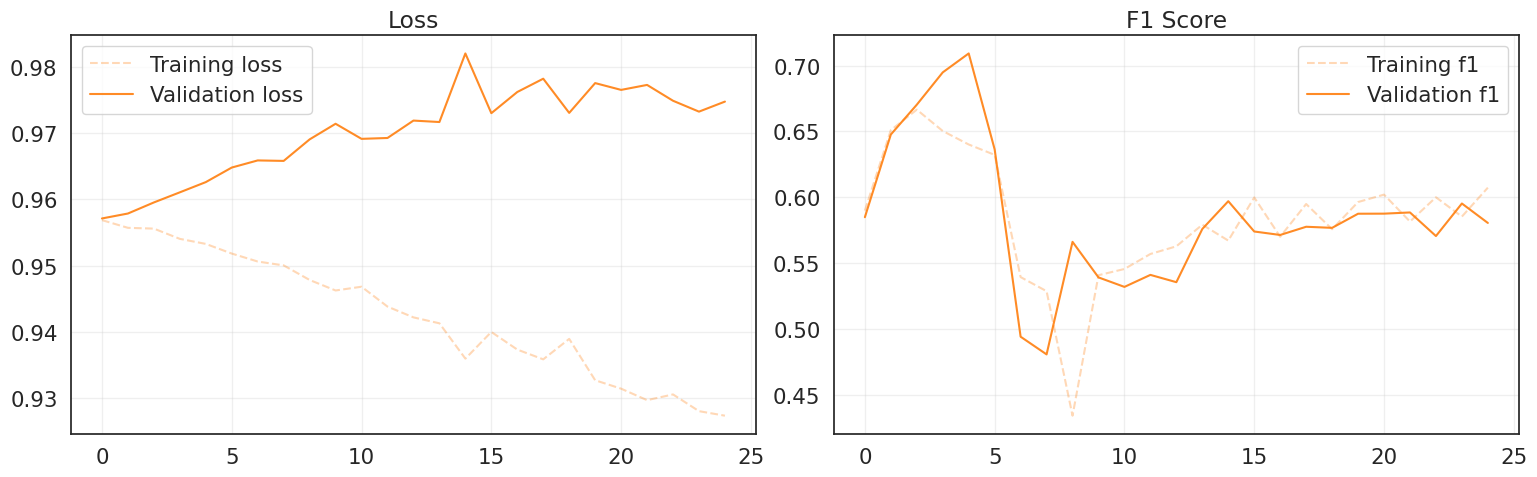

In [87]:
# @title Plot History
# Create a figure with two side-by-side subplots (two columns)
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(18, 5))

# Plot of training and validation loss on the first axis
ax1.plot(training_history['train_loss'], label='Training loss', alpha=0.3, color='#ff7f0e', linestyle='--')
ax1.plot(training_history['val_loss'], label='Validation loss', alpha=0.9, color='#ff7f0e')
ax1.set_title('Loss')
ax1.legend()
ax1.grid(alpha=0.3)

# Plot of training and validation accuracy on the second axis
ax2.plot(training_history['train_f1'], label='Training f1', alpha=0.3, color='#ff7f0e', linestyle='--')
ax2.plot(training_history['val_f1'], label='Validation f1', alpha=0.9, color='#ff7f0e')
ax2.set_title('F1 Score')
ax2.legend()
ax2.grid(alpha=0.3)

# Adjust the layout and display the plot
plt.tight_layout()
plt.subplots_adjust(right=0.85)
plt.show()

Classification Report:

              precision    recall  f1-score   support

      Tipo A       0.37      0.70      0.49       127
      Tipo B       0.81      0.97      0.88       311
      Tipo C       0.03      0.57      0.05        14
      Tipo D       0.06      0.44      0.11        27

   micro avg       0.37      0.86      0.51       479
   macro avg       0.32      0.67      0.38       479
weighted avg       0.63      0.86      0.71       479
 samples avg       0.39      0.88      0.52       479



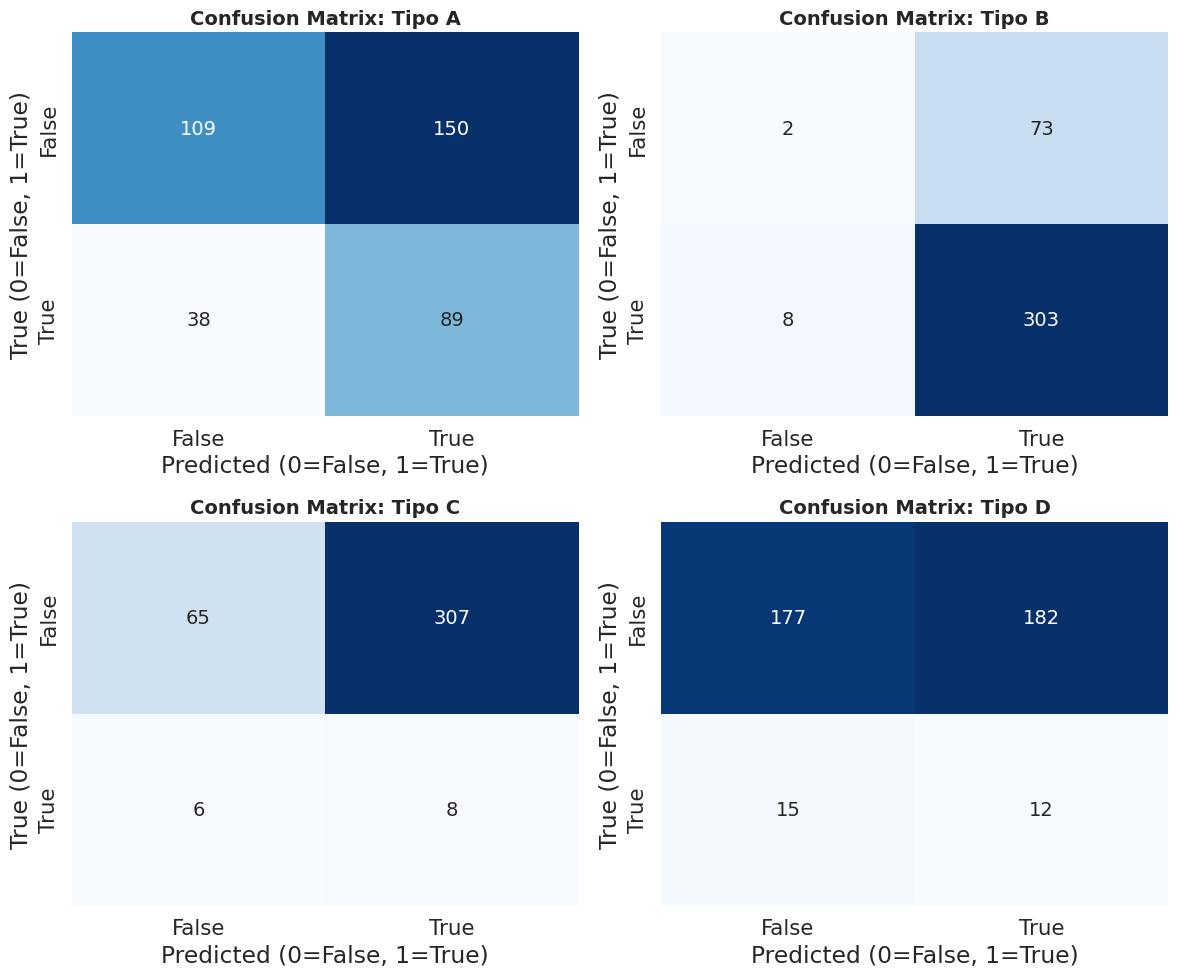

In [88]:
val_preds, val_targets = [], []
model.eval()

with torch.no_grad():
    for xb, yb in val_loader:
        xb = xb.to(device)

        # Forward pass
        logits = model(xb)

        probs = torch.sigmoid(logits)
        preds = (probs > 0.5).int()  # Convert probabilities to 0 or 1

        # Store batch results
        val_preds.append(preds.cpu().numpy())
        val_targets.append(yb.numpy())

# Combine into single arrays (Shape: [Samples, 4])
val_preds = np.vstack(val_preds)
val_targets = np.vstack(val_targets)

target_names = ['Tipo A', 'Tipo B', 'Tipo C', 'Tipo D']
print("Classification Report:\n")
print(classification_report(val_targets, val_preds, target_names=target_names, zero_division=0))

mcm = multilabel_confusion_matrix(val_targets, val_preds)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for i, (ax, cm) in enumerate(zip(axes, mcm)):
    # Create annotations (counts)
    labels = np.array([f"{num}" for num in cm.flatten()]).reshape(cm.shape)

    # Plot Heatmap
    sns.heatmap(cm, annot=labels, fmt='', cmap='Blues', ax=ax, cbar=False, annot_kws={"size": 14})

    # Formatting
    ax.set_title(f"Confusion Matrix: {target_names[i]}", fontsize=14, fontweight='bold')
    ax.set_xlabel('Predicted (0=False, 1=True)')
    ax.set_ylabel('True (0=False, 1=True)')
    ax.set_xticklabels(['False', 'True'])
    ax.set_yticklabels(['False', 'True'])

plt.tight_layout()
plt.show()

## 🕹️ **Inference**

In [89]:
test_preds, test_targets = [], []
best_model.eval()

with torch.no_grad():  # Disable gradient computation
    for xb, yb in test_loader:
        xb = xb.to(device)

        # Forward pass
        logits = best_model(xb)

        probs = torch.sigmoid(logits)
        preds = (probs > 0.5).int()

        # Store batch results
        test_preds.append(preds.cpu().numpy())
        test_targets.append(yb.numpy())

# Combine all batches into single arrays (Shape: [Samples, 4])
test_preds = np.vstack(test_preds)
test_targets = np.vstack(test_targets)

Accuracy (Exact Match) over the test set: 0.0385
Precision over the test set: 0.6224
Recall over the test set: 0.8660
F1 score over the test set: 0.7034

--- Detailed Classification Report ---
              precision    recall  f1-score   support

      Tipo A       0.35      0.67      0.46       128
      Tipo B       0.81      0.97      0.88       315
      Tipo C       0.04      0.86      0.07        14
      Tipo D       0.09      0.64      0.16        28

   micro avg       0.37      0.87      0.52       485
   macro avg       0.32      0.78      0.39       485
weighted avg       0.62      0.87      0.70       485
 samples avg       0.41      0.90      0.53       485



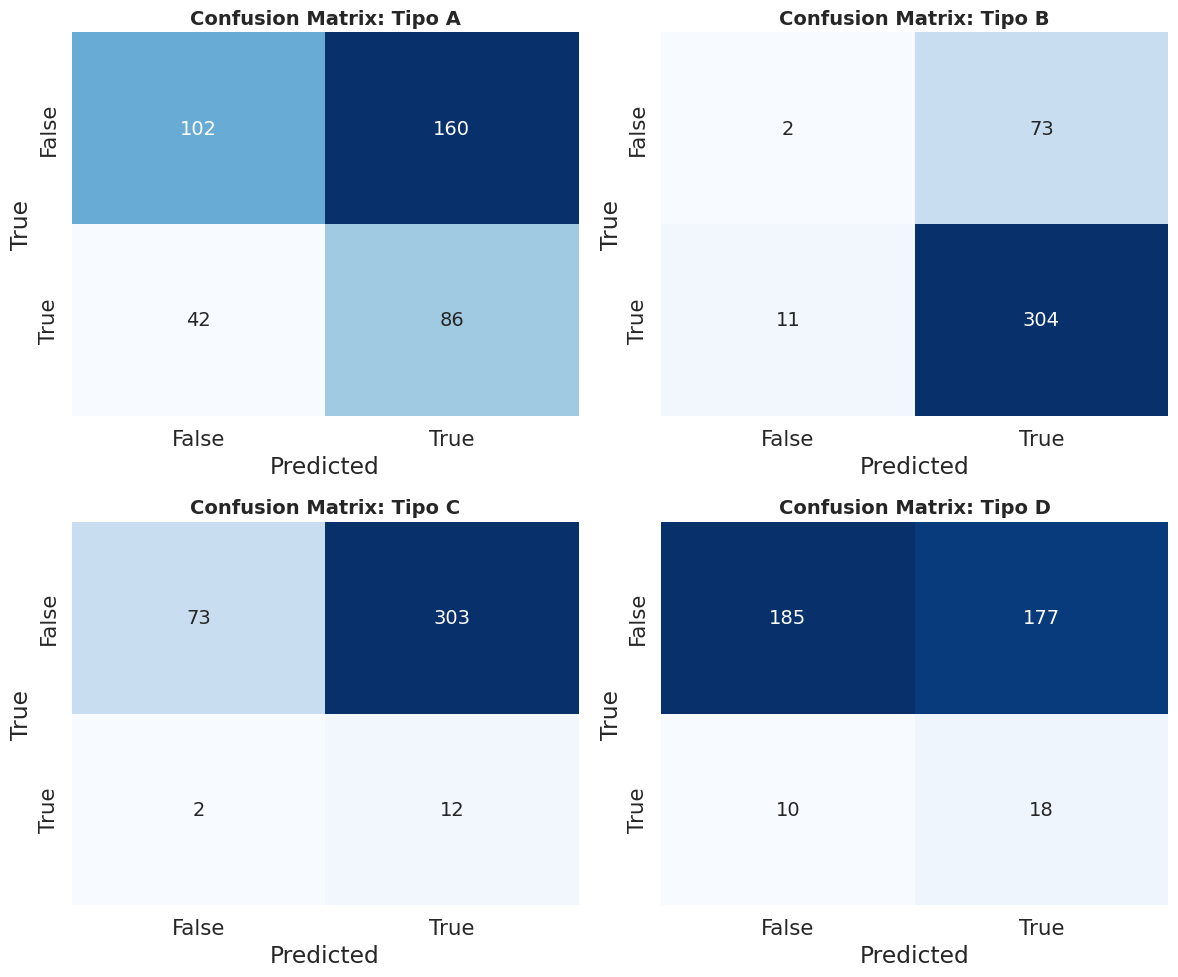

In [90]:
test_preds = np.vstack(test_preds)
test_targets = np.vstack(test_targets)

# Calculate Metrics
# Note: In multi-label, 'accuracy' means "Did you get ALL 4 labels right for this row?"
test_acc = accuracy_score(test_targets, test_preds)
test_prec = precision_score(test_targets, test_preds, average='weighted', zero_division=0)
test_rec = recall_score(test_targets, test_preds, average='weighted', zero_division=0)
test_f1 = f1_score(test_targets, test_preds, average='weighted', zero_division=0)

print(f"Accuracy (Exact Match) over the test set: {test_acc:.4f}")
print(f"Precision over the test set: {test_prec:.4f}")
print(f"Recall over the test set: {test_rec:.4f}")
print(f"F1 score over the test set: {test_f1:.4f}")

# Generate Classification Report (Per-Class Breakdown)
target_names = ['Tipo A', 'Tipo B', 'Tipo C', 'Tipo D']
print("\n--- Detailed Classification Report ---")
print(classification_report(test_targets, test_preds, target_names=target_names, zero_division=0))

# Visualization: Grid of 4 Confusion Matrices
# multilabel_confusion_matrix returns a shape of (4, 2, 2)
mcm = multilabel_confusion_matrix(test_targets, test_preds)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for i, (ax, cm) in enumerate(zip(axes, mcm)):
    # Create labels for annotations
    labels = np.array([f"{num}" for num in cm.flatten()]).reshape(cm.shape)

    # Plot Heatmap for this specific Class
    sns.heatmap(cm, annot=labels, fmt='', cmap='Blues', ax=ax, cbar=False, annot_kws={"size": 14})

    ax.set_title(f"Confusion Matrix: {target_names[i]}", fontsize=14, fontweight='bold')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_xticklabels(['False', 'True'])
    ax.set_yticklabels(['False', 'True'])

plt.tight_layout()
plt.show()

# **Clean Dataset** ML analysis

In [91]:
SERVIZI_CLEAN

,Tipo via,Via,Civico,Codice via,ZD,Superficie altri usi,Superficie lavorativa,Tipo A,Tipo B,Tipo C,Tipo D
0,VIA,ABAMONTI GIUSEPPE,1,3135,3,6.0,16.00,False,True,False,False
1,VIA,ABAMONTI GIUSEPPE,2,3135,3,3.0,126.00,True,True,False,False
2,VIA,ABBAZIA,6,1310,2,5.0,26.00,False,True,False,False
3,VLE,ABRUZZI,16,2177,3,0.0,55.68,True,True,False,False
4,VLE,ABRUZZI,25,2177,3,12.0,22.00,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...
3243,VIA,ZURETTI GIANFRANCO,31,1216,2,0.0,34.50,False,False,True,False
3244,VIA,ZURETTI GIANFRANCO,35,1216,2,0.0,47.00,False,False,False,True
3245,VIA,ZURETTI GIANFRANCO,42,1216,2,2.0,16.00,False,True,False,False
3246,VIA,ZURETTI GIANFRANCO,49,1216,2,11.0,35.00,False,True,False,False


Data Preprocessing

In [92]:
feature_cols = ['ZD', 'Tipo via', 'Superficie altri usi', 'Superficie lavorativa']
target_cols = ['Tipo A', 'Tipo B', 'Tipo C', 'Tipo D']

df = SERVIZI_CLEAN[feature_cols + target_cols].copy()

In [93]:
# Convert to numeric, turning any text errors (unclear ZD) into NaN
df['ZD'] = pd.to_numeric(df['ZD'], errors='coerce')

# Convert ZD to integer
df['ZD'] = df['ZD'].fillna(0).astype(int)

In [94]:
skewed_cols = ['Superficie altri usi', 'Superficie lavorativa']
for col in skewed_cols:
    df[col] = np.log1p(df[col])

In [95]:
df['ZD'] = df['ZD'].astype(str)
df['Tipo via'] = df['Tipo via'].astype(str).str.upper().str.strip()

In [96]:
df = pd.get_dummies(df, columns=['ZD', 'Tipo via'], dtype=float)

In [97]:
for col in target_cols:
    print(f"\nAnalyzing Target: {col}")
    target = df[col].fillna(0).astype(int).values

    print(f'Target shape: {target.shape}')

    unique, count = np.unique(target, return_counts=True)

    print('Target labels:', unique)
    for i in range(len(unique)):
        label = "True (1)" if unique[i] == 1 else "False (0)"
        print(f'Class {unique[i]} ({label}) has {count[i]} samples')


Analyzing Target: Tipo A
Target shape: (3248,)
Target labels: [0 1]
Class 0 (False (0)) has 2051 samples
Class 1 (True (1)) has 1197 samples

Analyzing Target: Tipo B
Target shape: (3248,)
Target labels: [0 1]
Class 0 (False (0)) has 519 samples
Class 1 (True (1)) has 2729 samples

Analyzing Target: Tipo C
Target shape: (3248,)
Target labels: [0 1]
Class 0 (False (0)) has 3109 samples
Class 1 (True (1)) has 139 samples

Analyzing Target: Tipo D
Target shape: (3248,)
Target labels: [0 1]
Class 0 (False (0)) has 2977 samples
Class 1 (True (1)) has 271 samples


In [98]:
from collections import Counter

X = df.drop(columns=target_cols).astype(np.float32).values
y = df[target_cols].astype(np.float32).values

y_strat = np.array(["".join(map(str, row.astype(int))) for row in y])

counts = Counter(y_strat)
singletons = {k for k, v in counts.items() if v < 2}
mask = ~np.isin(y_strat, list(singletons))

X = X[mask]
y = y[mask]
y_strat = y_strat[mask]

# Split (Train+Val / Test)
X_train_val, X_test, y_train_val, y_test, y_strat_train, _ = train_test_split(
    X, y, y_strat, test_size=0.1, random_state=42, stratify=y_strat
)

# Split (Train / Val)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.11, random_state=42, stratify=y_strat_train
)

print(f'Training set shape: {X_train.shape}')

Training set shape: (2600, 27)


In [99]:
input_features = X_train.shape[1]
print(f'Number of input features: {input_features}')

num_classes = y_train.shape[1]
print(f'Number of classes (output labels): {num_classes}')

Number of input features: 27
Number of classes (output labels): 4


In [100]:
epsilon = 1e-8

# Calculate stats ONLY on training set to avoid leakage
mean_train = X_train.mean(axis=0)
std_train = X_train.std(axis=0)

def manual_standardize(data, mean, std):
    return (data - mean) / (std + epsilon)

X_train = manual_standardize(X_train, mean_train, std_train)
X_val   = manual_standardize(X_val,   mean_train, std_train)
X_test  = manual_standardize(X_test,  mean_train, std_train)

print(f"X_train mean (should be ~0): {X_train.mean():.4f}")
print(f"X_train std (should be ~1):  {X_train.std():.4f}")

X_train mean (should be ~0): 0.0000
X_train std (should be ~1):  1.0000


In [101]:
# Convert numpy arrays to PyTorch datasets (pairs features with labels)
train_ds = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train))
val_ds   = TensorDataset(torch.from_numpy(X_val), torch.from_numpy(y_val))
test_ds  = TensorDataset(torch.from_numpy(X_test), torch.from_numpy(y_test))

In [102]:
# Define the batch size, which is the number of samples in each batch
BATCH_SIZE = 16

In [103]:
def make_loader(ds, batch_size, shuffle, drop_last):
    # Determine optimal number of worker processes for data loading
    cpu_cores = os.cpu_count() or 2
    num_workers = max(2, min(4, cpu_cores))

    # Create DataLoader with performance optimizations
    return DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers,
        pin_memory=True,  # Faster GPU transfer
        pin_memory_device="cuda" if torch.cuda.is_available() else "",
        prefetch_factor=4,  # Load 4 batches ahead
    )

In [104]:
# Create data loaders with different settings for each phase
train_loader = make_loader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=False)
val_loader   = make_loader(val_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)
test_loader  = make_loader(test_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)

In [105]:
# Get one batch from the training data loader
for xb, yb in train_loader:
    print("Features batch shape:", xb.shape)
    print("Labels batch shape:", yb.shape)
    break # Stop after getting one batch

Features batch shape: torch.Size([16, 27])
Labels batch shape: torch.Size([16, 4])


## 🛠️ **Model Building**

In [106]:
# Model architecture configuration
HIDDEN_LAYERS = 2
HIDDEN_SIZE = 256

In [107]:
y_train_t = torch.tensor(y_train, device=device)

num_positives = y_train_t.sum(dim=0)
num_negatives = len(y_train_t) - num_positives
pos_weight = (num_negatives / (num_positives + 1e-5))

print("Calculated Class Weights:", pos_weight)

Calculated Class Weights: tensor([ 1.7112,  0.1905, 22.6364, 11.0370])


In [108]:
# Training configuration, same as original dataset
LEARNING_RATE = 1e-5
EPOCHS = 500

PATIENCE = 20

L2_LAMBDA = 1e-4
DROPOUT_RATE = 0.3

# Set up loss function and optimizer
model = FeedForwardNet(
    in_features=input_features,
    hidden_layers=HIDDEN_LAYERS,
    hidden_size=HIDDEN_SIZE,
    dropout_rate=DROPOUT_RATE,
    num_classes=num_classes
).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=L2_LAMBDA)

# Enable mixed precision training for GPU acceleration
scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

summary(model, input_size=(input_features,))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Linear-1                  [-1, 256]           7,168
           Dropout-2                  [-1, 256]               0
              ReLU-3                  [-1, 256]               0
            Linear-4                  [-1, 256]          65,792
           Dropout-5                  [-1, 256]               0
              ReLU-6                  [-1, 256]               0
            Linear-7                  [-1, 256]          65,792
           Dropout-8                  [-1, 256]               0
              ReLU-9                  [-1, 256]               0
           Linear-10                    [-1, 4]           1,028
Total params: 139,780
Trainable params: 139,780
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.00
Forward/backward pass size (MB): 0.02
Params size (MB): 0.53
Estimated T

In [109]:
# Set up TensorBoard logging and save model architecture
experiment_name = "baseline_clean"
writer = SummaryWriter("./"+logs_dir+"/"+experiment_name)
x = torch.randn(1, input_features).to(device)
writer.add_graph(model, x)
writer.close()

In [110]:
%%time
# Train model and track training history
model, training_history = fit(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=EPOCHS,
    criterion=criterion,
    optimizer=optimizer,
    scaler=scaler,
    device=device,
    writer=writer,
    patience=PATIENCE,
    l2_lambda=L2_LAMBDA,
    verbose=1,
    experiment_name=experiment_name
    )

# Update best model if current performance is superior
if max(training_history['val_f1']) > best_performance:
    best_model = model
    best_performance = max(training_history['val_f1'])
    print(f"New best performance: {best_performance:.4f}")

Training 500 epochs...
Epoch   1/500 | Train: Loss=0.9506, F1 Score=0.6398 | Val: Loss=0.9313, F1 Score=0.6565
Epoch   2/500 | Train: Loss=0.9504, F1 Score=0.6401 | Val: Loss=0.9310, F1 Score=0.6596
Epoch   3/500 | Train: Loss=0.9495, F1 Score=0.6434 | Val: Loss=0.9308, F1 Score=0.6635
Epoch   4/500 | Train: Loss=0.9495, F1 Score=0.6424 | Val: Loss=0.9305, F1 Score=0.6836
Epoch   5/500 | Train: Loss=0.9469, F1 Score=0.6560 | Val: Loss=0.9301, F1 Score=0.7133
Epoch   6/500 | Train: Loss=0.9477, F1 Score=0.6542 | Val: Loss=0.9300, F1 Score=0.7098
Epoch   7/500 | Train: Loss=0.9480, F1 Score=0.6587 | Val: Loss=0.9298, F1 Score=0.7343
Epoch   8/500 | Train: Loss=0.9467, F1 Score=0.6695 | Val: Loss=0.9295, F1 Score=0.7344
Epoch   9/500 | Train: Loss=0.9460, F1 Score=0.6721 | Val: Loss=0.9292, F1 Score=0.7416
Epoch  10/500 | Train: Loss=0.9444, F1 Score=0.6708 | Val: Loss=0.9288, F1 Score=0.7404
Epoch  11/500 | Train: Loss=0.9456, F1 Score=0.6733 | Val: Loss=0.9285, F1 Score=0.7461
Epoch  12

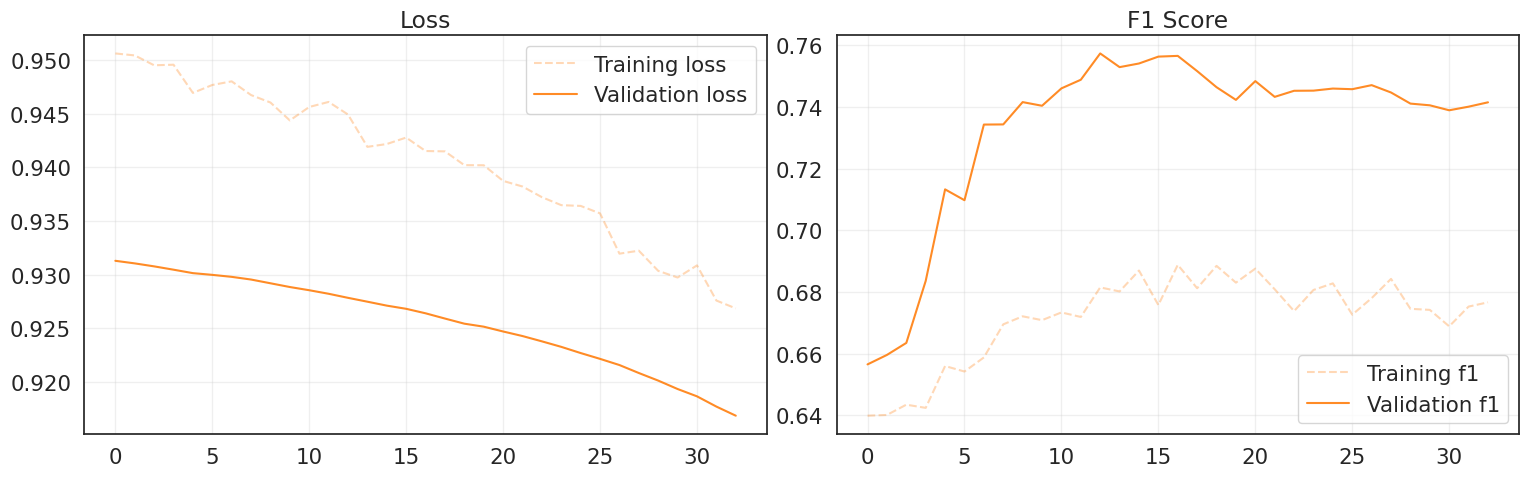

In [111]:
# @title Plot History
# Create a figure with two side-by-side subplots (two columns)
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(18, 5))

# Plot of training and validation loss on the first axis
ax1.plot(training_history['train_loss'], label='Training loss', alpha=0.3, color='#ff7f0e', linestyle='--')
ax1.plot(training_history['val_loss'], label='Validation loss', alpha=0.9, color='#ff7f0e')
ax1.set_title('Loss')
ax1.legend()
ax1.grid(alpha=0.3)

# Plot of training and validation accuracy on the second axis
ax2.plot(training_history['train_f1'], label='Training f1', alpha=0.3, color='#ff7f0e', linestyle='--')
ax2.plot(training_history['val_f1'], label='Validation f1', alpha=0.9, color='#ff7f0e')
ax2.set_title('F1 Score')
ax2.legend()
ax2.grid(alpha=0.3)

# Adjust the layout and display the plot
plt.tight_layout()
plt.subplots_adjust(right=0.85)
plt.show()

Classification Report:

              precision    recall  f1-score   support

      Tipo A       0.66      0.63      0.64       118
      Tipo B       0.84      0.98      0.90       271
      Tipo C       0.00      0.00      0.00        14
      Tipo D       0.12      0.26      0.17        27

   micro avg       0.71      0.81      0.75       430
   macro avg       0.41      0.47      0.43       430
weighted avg       0.72      0.81      0.76       430
 samples avg       0.76      0.84      0.77       430



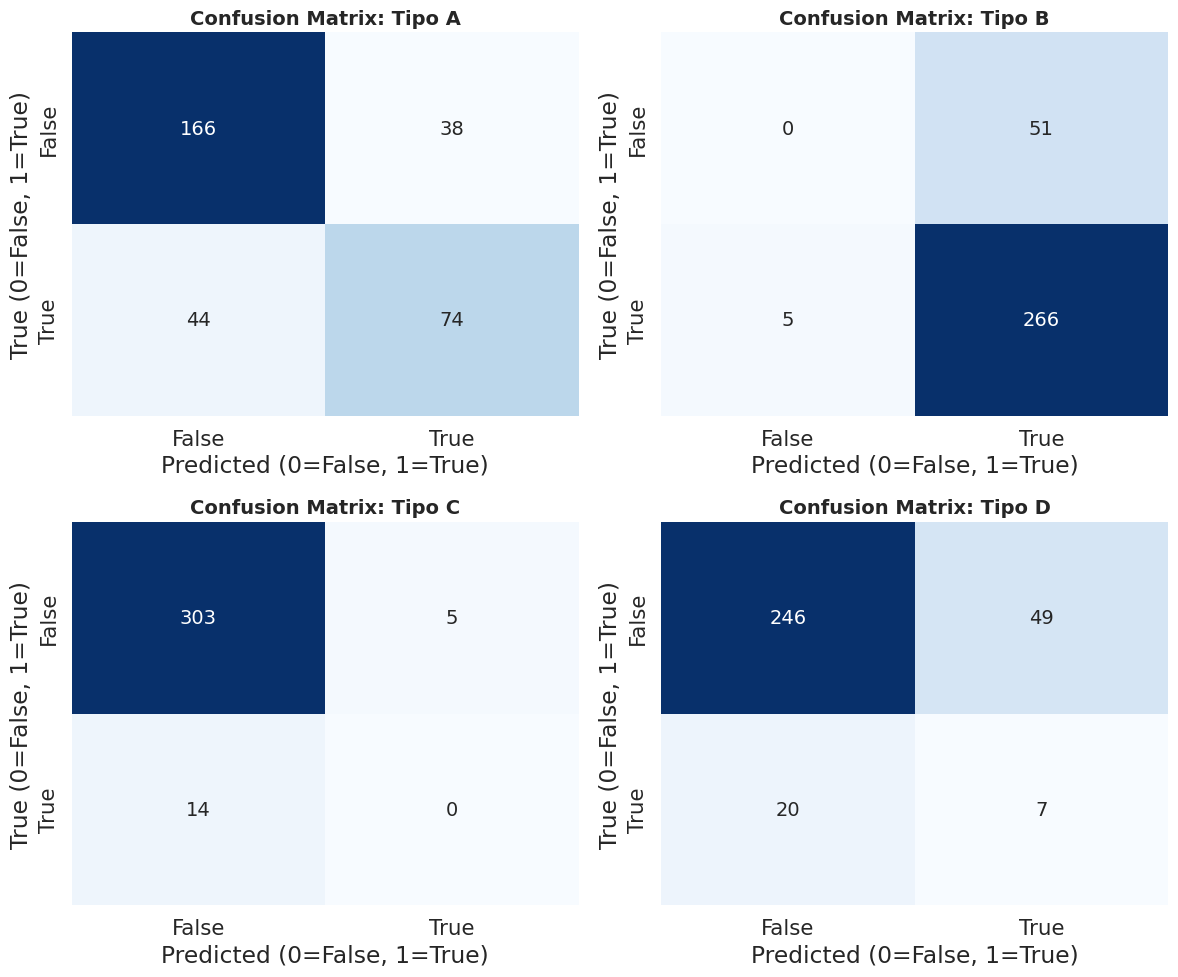

In [112]:
val_preds, val_targets = [], []
model.eval()

with torch.no_grad():
    for xb, yb in val_loader:
        xb = xb.to(device)

        # Forward pass
        logits = model(xb)

        probs = torch.sigmoid(logits)
        preds = (probs > 0.5).int()  # Convert probabilities to 0 or 1

        # Store batch results
        val_preds.append(preds.cpu().numpy())
        val_targets.append(yb.numpy())

# Combine into single arrays (Shape: [Samples, 4])
val_preds = np.vstack(val_preds)
val_targets = np.vstack(val_targets)

target_names = ['Tipo A', 'Tipo B', 'Tipo C', 'Tipo D']
print("Classification Report:\n")
print(classification_report(val_targets, val_preds, target_names=target_names, zero_division=0))

mcm = multilabel_confusion_matrix(val_targets, val_preds)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for i, (ax, cm) in enumerate(zip(axes, mcm)):
    # Create annotations (counts)
    labels = np.array([f"{num}" for num in cm.flatten()]).reshape(cm.shape)

    # Plot Heatmap
    sns.heatmap(cm, annot=labels, fmt='', cmap='Blues', ax=ax, cbar=False, annot_kws={"size": 14})

    # Formatting
    ax.set_title(f"Confusion Matrix: {target_names[i]}", fontsize=14, fontweight='bold')
    ax.set_xlabel('Predicted (0=False, 1=True)')
    ax.set_ylabel('True (0=False, 1=True)')
    ax.set_xticklabels(['False', 'True'])
    ax.set_yticklabels(['False', 'True'])

plt.tight_layout()
plt.show()

## 🕹️ **Inference**

In [113]:
test_preds, test_targets = [], []
best_model.eval()

with torch.no_grad():  # Disable gradient computation
    for xb, yb in test_loader:
        xb = xb.to(device)

        # Forward pass
        logits = best_model(xb)

        probs = torch.sigmoid(logits)
        preds = (probs > 0.5).int()

        # Store batch results
        test_preds.append(preds.cpu().numpy())
        test_targets.append(yb.numpy())

# Combine all batches into single arrays (Shape: [Samples, 4])
test_preds = np.vstack(test_preds)
test_targets = np.vstack(test_targets)

Accuracy (Exact Match) over the test set: 0.5292
Precision over the test set: 0.7128
Recall over the test set: 0.7834
F1 score over the test set: 0.7422

--- Detailed Classification Report ---
              precision    recall  f1-score   support

      Tipo A       0.62      0.53      0.57       120
      Tipo B       0.84      0.98      0.91       273
      Tipo C       0.00      0.00      0.00        14
      Tipo D       0.20      0.37      0.26        27

   micro avg       0.72      0.78      0.75       434
   macro avg       0.41      0.47      0.43       434
weighted avg       0.71      0.78      0.74       434
 samples avg       0.77      0.83      0.77       434



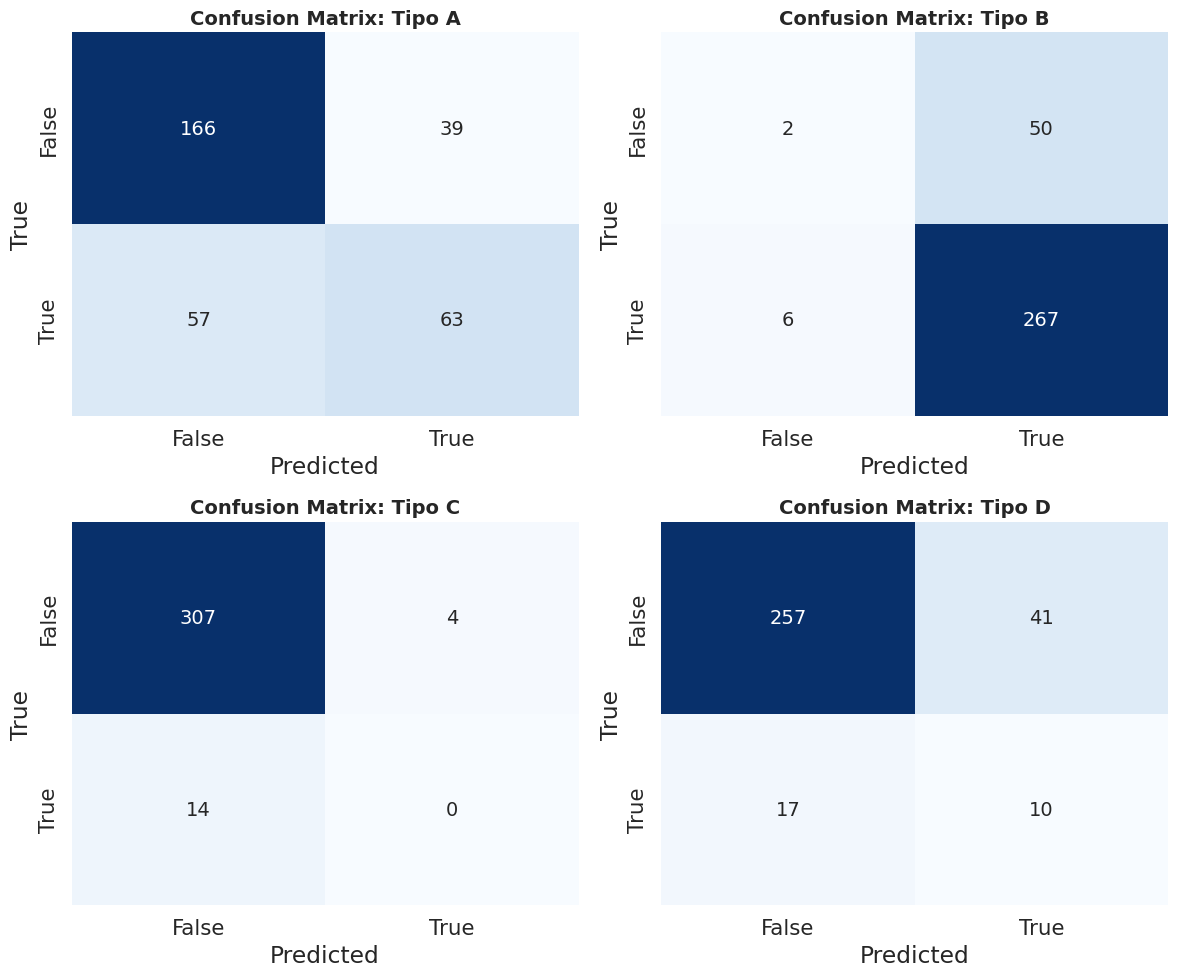

In [114]:
test_preds = np.vstack(test_preds)
test_targets = np.vstack(test_targets)

# Calculate Metrics
# Note: In multi-label, 'accuracy' means "Did you get ALL 4 labels right for this row?"
test_acc = accuracy_score(test_targets, test_preds)
test_prec = precision_score(test_targets, test_preds, average='weighted', zero_division=0)
test_rec = recall_score(test_targets, test_preds, average='weighted', zero_division=0)
test_f1 = f1_score(test_targets, test_preds, average='weighted', zero_division=0)

print(f"Accuracy (Exact Match) over the test set: {test_acc:.4f}")
print(f"Precision over the test set: {test_prec:.4f}")
print(f"Recall over the test set: {test_rec:.4f}")
print(f"F1 score over the test set: {test_f1:.4f}")

# Generate Classification Report (Per-Class Breakdown)
target_names = ['Tipo A', 'Tipo B', 'Tipo C', 'Tipo D']
print("\n--- Detailed Classification Report ---")
print(classification_report(test_targets, test_preds, target_names=target_names, zero_division=0))

# Visualization: Grid of 4 Confusion Matrices
# multilabel_confusion_matrix returns a shape of (4, 2, 2)
mcm = multilabel_confusion_matrix(test_targets, test_preds)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for i, (ax, cm) in enumerate(zip(axes, mcm)):
    # Create labels for annotations
    labels = np.array([f"{num}" for num in cm.flatten()]).reshape(cm.shape)

    # Plot Heatmap for this specific Class
    sns.heatmap(cm, annot=labels, fmt='', cmap='Blues', ax=ax, cbar=False, annot_kws={"size": 14})

    ax.set_title(f"Confusion Matrix: {target_names[i]}", fontsize=14, fontweight='bold')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_xticklabels(['False', 'True'])
    ax.set_yticklabels(['False', 'True'])

plt.tight_layout()
plt.show()